# What do DINOv3, CLIP and I-JEPA "see"? Sparse autoencoders on patch features

Three popular vision backbones are trained in very different ways:

| Model | Objective | Supervision |
|---|---|---|
| **DINOv3** ViT-B/16 | self-distillation (image + patch level) + Gram anchoring | none (images only) |
| **CLIP** ViT-B/16 | contrastive image-text matching of the *global* embedding | captions |
| **I-JEPA** ViT-H/14 | predict the *latent* representation of masked image regions | none (images only) |

We train one **TopK sparse autoencoder (SAE)** on the final-layer patch tokens of each model, with the same
dictionary size and sparsity, and then compare the dictionaries:

1. **How good are the SAEs?** reconstruction, dead latents, training curves.
2. **What kind of concept is each latent?** We use COCO instance masks to measure, for every latent, how
   category-pure it is, whether it covers *whole* objects or only *parts*, whether it fires on background
   ("stuff"), on object boundaries, on fixed image positions, everywhere in an image, or on high-norm artifact tokens.
   This gives a taxonomy of latent types per model, and answers *"does JEPA learn more object-level concepts than CLIP?"*
3. **Does each model have a dedicated latent for each COCO category?** (single-latent segmentation F1 for 80 classes)
4. **Which concepts are shared?** We correlate the activations of every latent pair across models on the
   same image patches, and calibrate "shared" with a *seed control* (two SAEs on the same model).
5. **Feature visualisations**: top-activating images, cross-model concept triplets, model-unique concepts and
   "SAE segmentation" maps.
6. **Is it the layer?** A depth sweep of patch-level probes, and a fourth SAE on I-JEPA's best intermediate layer.
7. **Context**: linear CKA between raw features, and a patch-level linear probe on raw features vs. SAE codes.

Everything runs on a single Kaggle T4 GPU. Knobs are in the next cell.

In [1]:
import os, gc, math, time, json, subprocess
subprocess.run("pip install -q -U timm pycocotools", shell=True)

import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from pycocotools.coco import COCO
import timm, transformers
from transformers import CLIPVisionModel, AutoModel, AutoImageProcessor
transformers.logging.set_verbosity_error()

# ---------------- knobs ----------------
SMOKE = False                  # tiny run to test every code path
N_TRAIN_IMAGES = 25000         # COCO train2017 images used to train the SAEs
TOKENS_PER_TRAIN_IMAGE = 128   # random patch tokens kept per training image (same for every model)
N_VAL_IMAGES = 5000            # COCO val2017 images (with masks) used for all analysis
IMG = 224
N_LATENTS = 8192               # same dictionary size for every model
TOPK = 32                      # active latents per token
BATCH = 4096
SAE_STEPS = 12000
LR = 3e-4
AUX_K, AUX_COEF = 256, 1 / 32  # auxiliary loss that revives dead latents (Gao et al. 2024)
DEAD_AFTER_TOKENS = 10_000_000
CONTROL_MODEL = 'DINOv3'       # also train a 2nd SAE (different seed) on this model as a "same model" baseline
SEED = 0

# analysis thresholds
MIN_COUNT = 50                 # latents active on fewer val tokens are "rare"
MIN_INST_PATCHES = 6           # objects smaller than this are ignored for part/whole coverage
SHARED_CORR = 0.5              # a latent is "shared" with a model if its best-matching latent there has corr >= this
OUTLIER_FACTOR = 3.0           # "high-norm" token: norm > OUTLIER_FACTOR x median norm
TH = dict(positional=0.3,      # latent-type thresholds (section 5)
          artifact=0.5, spread=0.5, boundary=0.6, purity=0.5, coverage=0.5, super=0.5, stuff=0.9)
USE_CACHE = False              # reuse run_<model>.pt found under /kaggle/input (for development only)
N_SWEEP = 2000                 # val images used for the layer-sweep probe

if SMOKE:
    N_TRAIN_IMAGES, N_VAL_IMAGES, SAE_STEPS, DEAD_AFTER_TOKENS, MIN_COUNT, N_SWEEP = 600, 200, 300, 200_000, 5, 150

MODELS = {
    'DINOv3': dict(src='timm/vit_base_patch16_dinov3.lvd1689m', grid=14),
    'CLIP':   dict(src='openai/clip-vit-base-patch16', grid=14),
    'I-JEPA': dict(src='facebook/ijepa_vith14_1k', grid=16),
}
COLORS = {'DINOv3': '#2a78d6', 'CLIP': '#eb6834', 'I-JEPA': '#1baf7a'}
MAIN = list(MODELS)            # the three final-layer models (an intermediate-layer I-JEPA is added in section 3b)
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
OUT = '/kaggle/working' if os.path.exists('/kaggle/working') else './out'
FIG = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)
torch.manual_seed(SEED); np.random.seed(SEED)
try:  # keep the executed notebook small
    get_ipython().run_line_magic('config', "InlineBackend.figure_format = 'jpeg'")
except NameError:
    pass
plt.rcParams.update({'figure.dpi': 90, 'savefig.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
print(DEV, torch.cuda.get_device_name(0) if DEV == 'cuda' else '', '| timm', timm.__version__,
      '| transformers', transformers.__version__)
T0 = time.time()

def savefig(name):
    plt.savefig(f'{FIG}/{name}.png', bbox_inches='tight', dpi=130)
    plt.show()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 45.9 MB/s eta 0:00:00


cuda Tesla T4 | timm 1.0.30 | transformers 5.0.0


## 1. Data: COCO 2017
SAEs are trained on patches from `train2017` images; all analysis uses held-out `val2017` images, whose
instance masks give every patch a label. Images are resized (shorter side 224) and center-cropped to 224x224;
masks go through the exact same transform and are then averaged into each model's patch grid
(14x14 for the /16 models, 16x16 for I-JEPA's /14 patches).

In [2]:
def find_input(name):
    """Find a file/dir under /kaggle/input without walking the 160k COCO images."""
    for root, dirs, files in os.walk('/kaggle/input'):
        dirs[:] = [d for d in dirs if d not in ('train2017', 'val2017', 'test2017')]
        if name in files or name in dirs:
            return os.path.join(root, name)

COCO_DIR = find_input('coco2017')
print('COCO at', COCO_DIR)

def crop_geometry(w, h):
    s = IMG / min(w, h)
    nw, nh = max(IMG, round(w * s)), max(IMG, round(h * s))
    left, top = (nw - IMG) // 2, (nh - IMG) // 2
    return nw, nh, (left, top, left + IMG, top + IMG)

def load_img(path):
    im = Image.open(path)
    w, h = im.size
    im.draft('RGB', (IMG, IMG))  # fast JPEG decoding at reduced size (still >= IMG)
    nw, nh, box = crop_geometry(w, h)
    return np.asarray(im.convert('RGB').resize((nw, nh), Image.BICUBIC).crop(box))

class ImgDS(torch.utils.data.Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return torch.from_numpy(load_img(self.paths[i]).copy())

def load_images(paths):
    out = torch.empty(len(paths), IMG, IMG, 3, dtype=torch.uint8)
    dl = torch.utils.data.DataLoader(ImgDS(paths), batch_size=64, num_workers=4)
    i = 0
    for b in dl:
        out[i:i + len(b)] = b; i += len(b)
    return out

rng = np.random.default_rng(SEED)
train_files = sorted(os.listdir(f'{COCO_DIR}/train2017'))
train_paths = [f'{COCO_DIR}/train2017/{f}' for f in rng.choice(train_files, N_TRAIN_IMAGES, replace=False)]

coco = COCO(f'{COCO_DIR}/annotations/instances_val2017.json')
CAT_IDS = sorted(coco.getCatIds())
CAT_INDEX = {c: i for i, c in enumerate(CAT_IDS)}
CAT_NAMES = [coco.loadCats(c)[0]['name'] for c in CAT_IDS] + ['background']
SUPERS = sorted({coco.loadCats(c)[0]['supercategory'] for c in CAT_IDS})
CAT_SUPER = torch.tensor([SUPERS.index(coco.loadCats(c)[0]['supercategory']) for c in CAT_IDS])
BG = 80
val_ids = [int(i) for i in rng.choice(sorted(coco.getImgIds()), N_VAL_IMAGES, replace=False)]
val_paths = [f"{COCO_DIR}/val2017/{coco.loadImgs(i)[0]['file_name']}" for i in val_ids]

t = time.time()
TRAIN_IMGS = load_images(train_paths)
VAL_IMGS = load_images(val_paths)
print(f'images: train {tuple(TRAIN_IMGS.shape)}, val {tuple(VAL_IMGS.shape)}  ({time.time() - t:.0f}s)')

COCO at /kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017


loading annotations into memory...


Done (t=0.88s)
creating index...
index created!


images: train (25000, 224, 224, 3), val (5000, 224, 224, 3)  (118s)


In [3]:
GRIDS = sorted({m['grid'] for m in MODELS.values()})

def patch_labels(img_id, inst_offset):
    """Per patch: category (80 = background), instance id (-1 = none) and whether it lies on an object boundary."""
    info = coco.loadImgs(img_id)[0]
    nw, nh, box = crop_geometry(info['width'], info['height'])
    anns = [a for a in coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False)) if a['area'] > 0]
    cover = np.zeros((len(anns), IMG, IMG), np.float32)
    for n, a in enumerate(anns):
        m = Image.fromarray(coco.annToMask(a) * 255).resize((nw, nh), Image.BILINEAR).crop(box)
        cover[n] = np.asarray(m, np.float32) / 255
    cats = np.array([CAT_INDEX[a['category_id']] for a in anns], np.int64)
    out = {}
    for g in GRIDS:
        p = IMG // g
        if len(anns) == 0:
            out[g] = (np.full(g * g, BG), np.full(g * g, -1), np.zeros(g * g, bool))
            continue
        cov = cover.reshape(len(anns), g, p, g, p).mean((2, 4)).reshape(len(anns), g * g)
        best, bestv = cov.argmax(0), cov.max(0)
        cat = np.where(bestv >= 0.5, cats[best], BG)
        inst = np.where(bestv >= 0.5, best + inst_offset, -1)
        union = np.clip(cov.sum(0), 0, 1)
        out[g] = (cat, inst, (union > 0.2) & (union < 0.8))
    return out, len(anns)

t = time.time()
per_grid = {g: [] for g in GRIDS}
n_inst = 0
for img_id in val_ids:
    out, n = patch_labels(img_id, n_inst)
    n_inst += n
    for g in GRIDS:
        per_grid[g].append(out[g])
LABELS = {}
for g in GRIDS:
    cat, inst, bnd = (torch.tensor(np.stack(x)) for x in zip(*per_grid[g]))
    LABELS[g] = dict(cat=cat.long(), inst=inst.long(), boundary=bnd, n_inst=n_inst)
    frac_bg = (cat == BG).float().mean().item()
    print(f'grid {g}x{g}: {frac_bg:.1%} background patches, {bnd.float().mean():.1%} boundary patches')
del per_grid
print(f'labels: {time.time() - t:.0f}s')

grid 14x14: 67.7% background patches, 11.3% boundary patches
grid 16x16: 67.5% background patches, 10.3% boundary patches
labels: 101s


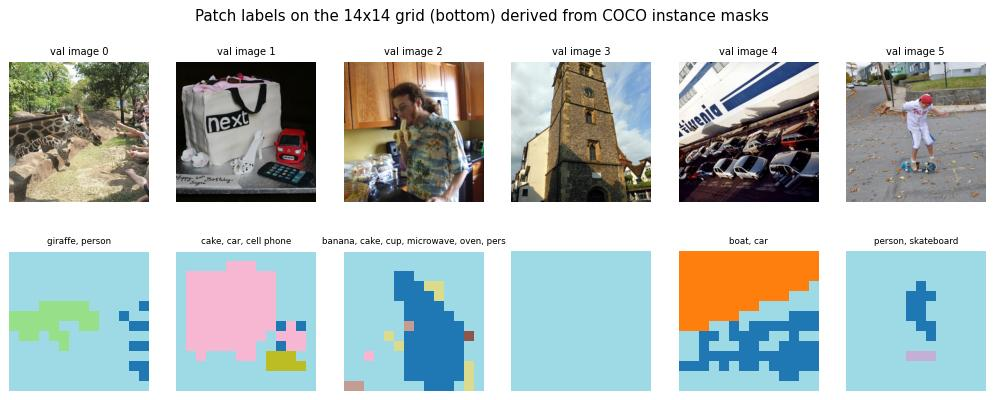

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for k, ax in enumerate(axes[0]):
    ax.imshow(VAL_IMGS[k]); ax.set_title(f'val image {k}', fontsize=8); ax.axis('off')
for k, ax in enumerate(axes[1]):
    ax.imshow(LABELS[14]['cat'][k].view(14, 14), cmap='tab20', vmin=0, vmax=80, interpolation='nearest')
    names = sorted({CAT_NAMES[c] for c in LABELS[14]['cat'][k].tolist() if c != BG})
    ax.set_title(', '.join(names)[:40], fontsize=7); ax.axis('off')
plt.suptitle('Patch labels on the 14x14 grid (bottom) derived from COCO instance masks')
savefig('patch_labels')

## 2. Backbones and patch features
We take the **final-layer patch tokens** of each model (DINOv3: after the final norm, dropping the CLS and 4
register tokens; CLIP: last transformer block, dropping CLS; I-JEPA: final layer, which has no CLS token).

Note that I-JEPA is only public as a ViT-H/14 (632M params, 1280-d) while the others are ViT-B/16 (86M, 768-d).
We keep the SAE dictionary size fixed at 8192 for all models so that the *number of concepts* is comparable.

In [5]:
def load_backbone(name):
    """Returns model, fn(x) -> patch tokens (final layer, or block `layer` if set), mean, std, blocks, #prefix tokens."""
    src, layer = MODELS[name]['src'], MODELS[name].get('layer')
    if src.startswith('timm/'):
        m = timm.create_model(src.replace('timm/', ''), pretrained=True)
        mean, std = m.pretrained_cfg['mean'], m.pretrained_cfg['std']
        blocks, prefix = m.blocks, m.num_prefix_tokens
        final = lambda x: m.forward_features(x)
    elif 'clip' in src:
        m = CLIPVisionModel.from_pretrained(src)
        proc = AutoImageProcessor.from_pretrained(src)
        mean, std = proc.image_mean, proc.image_std
        blocks, prefix = m.vision_model.encoder.layers, 1
        final = lambda x: m(pixel_values=x).last_hidden_state
    else:
        m = AutoModel.from_pretrained(src)
        proc = AutoImageProcessor.from_pretrained(src)
        mean, std = proc.image_mean, proc.image_std
        blocks, prefix = m.encoder.layer, 0
        final = lambda x: m(pixel_values=x).last_hidden_state
    m = m.to(DEV).eval()
    if layer is None:
        fn = lambda x: final(x)[:, prefix:]
    else:  # output of block `layer` (1-based), grabbed with a hook
        cache = {}
        blocks[layer - 1].register_forward_hook(
            lambda mod, inp, out: cache.update(h=out[0] if isinstance(out, tuple) else out))
        fn = lambda x: (final(x), cache['h'])[1][:, prefix:]
    return m, fn, mean, std, blocks, prefix

@torch.no_grad()
def extract(fn, mean, std, imgs, keep=None, bs=32):
    """Patch tokens for uint8 images -> fp16 CPU tensor (N, P, D), or (N * keep, D) random tokens if keep is set."""
    mean = torch.tensor(mean, device=DEV).view(1, 3, 1, 1)
    std = torch.tensor(std, device=DEV).view(1, 3, 1, 1)
    gen = torch.Generator().manual_seed(SEED)
    out = None
    for i in range(0, len(imgs), bs):
        x = imgs[i:i + bs].to(DEV).permute(0, 3, 1, 2).float().div(255).sub(mean).div(std)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
            t = fn(x).float()
        if keep:
            sel = torch.rand(t.shape[0], t.shape[1], generator=gen).argsort(1)[:, :keep].to(DEV)
            t = t.gather(1, sel[..., None].expand(-1, -1, t.shape[2]))
        if out is None:
            out = torch.empty((len(imgs),) + t.shape[1:], dtype=torch.float16)
        out[i:i + len(t)] = t.half().cpu()
    return out.flatten(0, 1) if keep else out

## 3. TopK sparse autoencoder
$z = \mathrm{TopK}_k\big(W_{enc}(x - b_{dec}) + b_{enc}\big)$, $\hat x = W_{dec} z + b_{dec}$, with unit-norm decoder
rows, $k=32$ and 8192 latents. Features are centred and scaled so that $E\|x\|^2 = d$, and we report the
**fraction of variance unexplained (FVU)**. An auxiliary TopK loss on dead latents keeps the dictionary alive.

In [6]:
class TopKSAE(nn.Module):
    def __init__(self, d, n, k):
        super().__init__()
        W = torch.randn(n, d)
        W = W / W.norm(dim=1, keepdim=True)
        self.W_dec = nn.Parameter(W.clone())
        self.W_enc = nn.Parameter(W.T.clone())
        self.b_enc = nn.Parameter(torch.zeros(n))
        self.b_dec = nn.Parameter(torch.zeros(d))
        self.k = k

    def pre(self, x):
        return (x - self.b_dec) @ self.W_enc + self.b_enc

    def encode(self, x):
        v, i = self.pre(x).topk(self.k, dim=-1)
        return F.relu(v), i

    def decode(self, v, i):
        z = torch.zeros(v.shape[0], self.W_dec.shape[0], device=v.device).scatter(1, i, v)
        return z @ self.W_dec + self.b_dec


def train_sae(X, seed):
    """X: normalised training tokens (T, d) fp16 on DEV."""
    torch.manual_seed(seed)
    T, d = X.shape
    sae = TopKSAE(d, N_LATENTS, TOPK).to(DEV)
    opt = torch.optim.Adam(sae.parameters(), lr=LR)
    scaler = torch.amp.GradScaler(enabled=DEV == 'cuda')
    warm, decay = 200, int(0.2 * SAE_STEPS)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1, (s + 1) / warm) * min(1, (SAE_STEPS - s) / decay))
    steps_since = torch.zeros(N_LATENTS, device=DEV)
    dead_steps = DEAD_AFTER_TOKENS // BATCH
    log = []
    t = time.time()
    for step in range(SAE_STEPS):
        x = X[torch.randint(0, T, (BATCH,), device=DEV)].float()
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
            pre = sae.pre(x).float()
            v, i = pre.topk(TOPK, dim=-1)
            v = F.relu(v)
            e = x - sae.decode(v, i).float()
        fvu = (e ** 2).sum(-1).mean() / (x ** 2).sum(-1).mean()
        loss = fvu

        fired = torch.zeros(N_LATENTS, dtype=torch.bool, device=DEV)
        fired[i[v > 0]] = True
        steps_since = torch.where(fired, 0, steps_since + 1)
        dead = steps_since > dead_steps
        if dead.any():
            va, ia = pre.masked_fill(~dead, -float('inf')).topk(min(AUX_K, int(dead.sum())), dim=-1)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
                e_hat = (torch.zeros_like(pre).scatter(1, ia, F.relu(va)) @ sae.W_dec).float()
            aux = ((e.detach() - e_hat) ** 2).sum(-1).mean() / (e.detach() ** 2).sum(-1).mean()
            loss = loss + AUX_COEF * aux

        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        with torch.no_grad():
            sae.W_dec /= sae.W_dec.norm(dim=1, keepdim=True)
        if step % 100 == 0 or step == SAE_STEPS - 1:
            log.append((step, fvu.item(), dead.float().mean().item()))
        if step % 2000 == 0:
            print(f'  step {step:6d}  fvu {fvu.item():.3f}  dead {dead.float().mean():.1%}  ({time.time() - t:.0f}s)')
    return sae.eval(), np.array(log)


@torch.no_grad()
def encode_all(sae, V, mu, scale):
    """Encode all val tokens (N, P, D) -> sparse codes (idx int16, val fp16) of shape (N, P, k), and val FVU."""
    N, P, D = V.shape
    idx = torch.empty(N, P, TOPK, dtype=torch.int16)
    val = torch.empty(N, P, TOPK, dtype=torch.float16)
    sse = sst = 0.0
    for s in range(0, N, 64):
        x = ((V[s:s + 64].to(DEV).float() - mu) / scale).flatten(0, 1)
        v, i = sae.encode(x)
        sse += ((x - sae.decode(v, i)) ** 2).sum().item()
        sst += (x ** 2).sum().item()
        idx[s:s + 64] = i.view(-1, P, TOPK).short().cpu()
        val[s:s + 64] = v.view(-1, P, TOPK).half().cpu()
    return idx, val, sse / sst

def norm_stats(X):
    """Mean vector and scalar scale such that E||(x - mu) / scale||^2 = d."""
    X = X.reshape(-1, X.shape[-1])
    ch = 2 ** 18
    mu = sum(X[s:s + ch].to(DEV).float().sum(0) for s in range(0, len(X), ch)) / len(X)
    ms = sum(((X[s:s + ch].to(DEV).float() - mu) ** 2).sum().item() for s in range(0, len(X), ch))
    return mu, math.sqrt(ms / X.numel())

### Patch-level linear probe (context)
How much COCO category information is *linearly* available in each model's patch tokens, and how much of it
survives in the 32-sparse SAE code? We fit an 81-way (80 things + background) linear classifier on 80% of the val
images and report patch accuracy and mean IoU on the remaining 20%.

In [7]:
def linear_probe(get_x, n_in, cats, epochs=10):
    N = cats.shape[0]
    n_tr = int(0.8 * N)
    torch.manual_seed(SEED)
    clf = nn.Linear(n_in, 81).to(DEV)
    opt = torch.optim.Adam(clf.parameters(), lr=3e-3)
    for ep in range(epochs):
        for b in torch.randperm(n_tr).split(32):
            loss = F.cross_entropy(clf(get_x(b)), cats[b].flatten().to(DEV))
            opt.zero_grad(); loss.backward(); opt.step()
    conf = torch.zeros(81 * 81, device=DEV)
    with torch.no_grad():
        for b in torch.arange(n_tr, N).split(64):
            y = cats[b].flatten().to(DEV)
            conf += torch.bincount(y * 81 + clf(get_x(b)).argmax(1), minlength=81 * 81).float()
    conf = conf.view(81, 81)
    tp = conf.diag()
    iou = tp / (conf.sum(0) + conf.sum(1) - tp)
    present = conf.sum(1) > 0
    return dict(acc=(tp.sum() / conf.sum()).item(), miou=iou[present].mean().item())

### Run everything per model
For each backbone: extract train tokens (128 random patches x 25k images) and all val tokens, train the SAE,
encode the val set, and run the probes. Only the sparse codes are kept in memory afterwards.

In [8]:
R = {}

def run_model(name):
    cache = find_input(f'run_{name}.pt') if USE_CACHE else None
    if cache:
        print(f'{name}: loading cached run from {cache}')
        return torch.load(cache, weights_only=False)
    t = time.time()
    model, fn, mean, std, _, _ = load_backbone(name)
    V = extract(fn, mean, std, VAL_IMGS)                                   # (N, P, D)
    X = extract(fn, mean, std, TRAIN_IMGS, keep=TOKENS_PER_TRAIN_IMAGE)    # (T, D)
    del model; gc.collect(); torch.cuda.empty_cache()
    print(f'{name}: val {tuple(V.shape)}, train {tuple(X.shape)} extracted in {time.time() - t:.0f}s')

    X = X.to(DEV)
    mu, scale = norm_stats(X)
    for s in range(0, len(X), 2 ** 18): X[s:s + 2 ** 18] = ((X[s:s + 2 ** 18].float() - mu) / scale).half()

    r = dict(grid=MODELS[name]['grid'], D=X.shape[1], mu=mu.cpu(), scale=scale)
    seeds = [SEED, SEED + 1] if name == CONTROL_MODEL else [SEED]
    for s in seeds:
        sae, log = train_sae(X, seed=s)
        idx, val, fvu = encode_all(sae, V, mu, scale)
        tag = '' if s == SEED else '_control'
        r.update({f'sae{tag}': {k: v.cpu() for k, v in sae.state_dict().items()},
                  f'log{tag}': log, f'idx{tag}': idx, f'val{tag}': val, f'fvu{tag}': fvu})
        print(f'{name} (seed {s}): val FVU {fvu:.3f}   [{time.time() - t:.0f}s]')
    del X; gc.collect(); torch.cuda.empty_cache()

    r['norms'] = V.float().norm(dim=-1)                                     # raw token norms (N, P)
    cats = LABELS[r['grid']]['cat']
    get_raw = lambda b: ((V[b].to(DEV).float() - mu) / scale).flatten(0, 1)
    def get_code(b):
        i, v = r['idx'][b].to(DEV).long().flatten(0, 1), r['val'][b].to(DEV).float().flatten(0, 1)
        return torch.zeros(len(i), N_LATENTS, device=DEV).scatter(1, i, v)
    r['probe_raw'] = linear_probe(get_raw, r['D'], cats)
    r['probe_sae'] = linear_probe(get_code, N_LATENTS, cats)
    print(f"{name}: probe raw {r['probe_raw']}  sae {r['probe_sae']}")

    # raw features of the first 1000 val images on a common 14x14 grid, for CKA
    n_cka = min(1000, len(V))
    Vc = V[:n_cka].float()
    g = r['grid']
    if g != 14:
        Vc = F.adaptive_avg_pool2d(Vc.view(n_cka, g, g, -1).permute(0, 3, 1, 2), 14).permute(0, 2, 3, 1)
    r['cka_x'] = Vc.reshape(-1, Vc.shape[-1]).half()
    del V, Vc; gc.collect()
    torch.save(r, f'{OUT}/run_{name}.pt')
    print(f'{name} done in {time.time() - t:.0f}s')
    return r

for name in MAIN:
    R[name] = run_model(name)
print(f'total so far: {(time.time() - T0) / 60:.1f} min')

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

DINOv3: val (5000, 196, 768), train (3200000, 768) extracted in 111s


  step      0  fvu 0.763  dead 0.0%  (0s)


  step   2000  fvu 0.228  dead 0.0%  (58s)


  step   4000  fvu 0.203  dead 0.0%  (116s)


...

  step   8000  fvu 0.184  dead 0.0%  (324s)


  step  10000  fvu 0.182  dead 0.0%  (405s)


I-JEPA (seed 0): val FVU 0.193   [1093s]


I-JEPA: probe raw {'acc': 0.8174335956573486, 'miou': 0.3181430399417877}  sae {'acc': 0.8187187314033508, 'miou': 0.28584593534469604}


I-JEPA done in 1129s
total so far: 44.5 min


### 3b. Is it the layer? A depth sweep
The final layer is not necessarily where a model keeps its most object-like patch features (I-JEPA's final layer,
in particular, is trained to be *predictable from context*, not to be linearly decodable). We probe patch tokens
at 7 relative depths of every model (same linear probe, 2000 val images), then train one more SAE on I-JEPA at
its best intermediate layer and push it through the whole analysis as a fourth dictionary.

DINOv3  layer  2/12: probe mIoU 0.036


DINOv3  layer  4/12: probe mIoU 0.073


DINOv3  layer  6/12: probe mIoU 0.142


DINOv3  layer  8/12: probe mIoU 0.261


DINOv3  layer 10/12: probe mIoU 0.333


...

I-JEPA  layer 16/32: probe mIoU 0.107


I-JEPA  layer 21/32: probe mIoU 0.164


I-JEPA  layer 27/32: probe mIoU 0.245


I-JEPA  layer 29/32: probe mIoU 0.258


I-JEPA  layer 32/32: probe mIoU 0.253


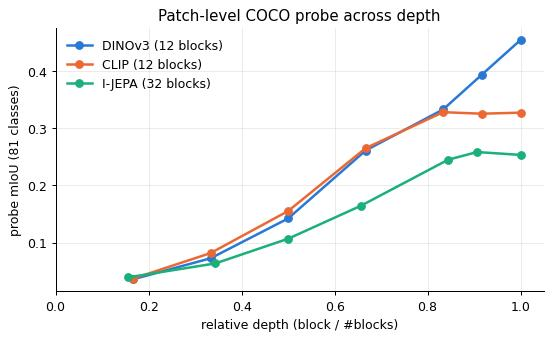

training an extra SAE on I-JEPA L29


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

I-JEPA L29: val (5000, 256, 1280), train (3200000, 1280) extracted in 577s


  step      0  fvu 0.826  dead 0.0%  (0s)


  step   2000  fvu 0.257  dead 0.0%  (81s)


...

  step  10000  fvu 0.221  dead 0.0%  (405s)


I-JEPA L29 (seed 0): val FVU 0.233   [1084s]


I-JEPA L29: probe raw {'acc': 0.8221172094345093, 'miou': 0.3385784924030304}  sae {'acc': 0.82958984375, 'miou': 0.30770641565322876}


I-JEPA L29 done in 1119s


total so far: 65.7 min


In [9]:
@torch.no_grad()
def sweep_features(name):
    model, fn, mean, std, blocks, prefix = load_backbone(name)
    layers = sorted({max(1, round(f * len(blocks))) for f in [1 / 6, 2 / 6, 3 / 6, 4 / 6, 5 / 6, 11 / 12, 1]})
    cache = {}
    hooks = [blocks[l - 1].register_forward_hook(
        lambda mod, inp, out, l=l: cache.update({l: out[0] if isinstance(out, tuple) else out})) for l in layers]
    mean = torch.tensor(mean, device=DEV).view(1, 3, 1, 1); std = torch.tensor(std, device=DEV).view(1, 3, 1, 1)
    feats = {}
    for i in range(0, N_SWEEP, 32):
        x = VAL_IMGS[i:min(i + 32, N_SWEEP)].to(DEV).permute(0, 3, 1, 2).float().div(255).sub(mean).div(std)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
            fn(x)
        for l in layers:
            h = cache[l][:, prefix:].half().cpu()
            if l not in feats: feats[l] = torch.empty((N_SWEEP,) + h.shape[1:], dtype=torch.float16)
            feats[l][i:i + len(h)] = h
    for h in hooks: h.remove()
    del model; gc.collect(); torch.cuda.empty_cache()
    return feats, len(blocks)

N_SWEEP = min(N_SWEEP, N_VAL_IMAGES)
SWEEP = {}
for name in MAIN:
    feats, depth = sweep_features(name)
    cats = LABELS[MODELS[name]['grid']]['cat'][:N_SWEEP]
    SWEEP[name] = []
    for l, V in feats.items():
        mu, scale = norm_stats(V)
        res = linear_probe(lambda b: ((V[b].to(DEV).float() - mu) / scale).flatten(0, 1), V.shape[-1], cats)
        SWEEP[name].append((l, depth, res['miou']))
        print(f'{name:7s} layer {l:2d}/{depth}: probe mIoU {res["miou"]:.3f}')
    del feats, V; gc.collect()

fig, ax = plt.subplots(figsize=(7, 3.8))
for name in MAIN:
    l, d, miou = np.array(SWEEP[name]).T
    ax.plot(l / d, miou, '-o', color=COLORS[name], lw=2, ms=6, label=f'{name} ({int(d[0])} blocks)')
ax.set(xlabel='relative depth (block / #blocks)', ylabel='probe mIoU (81 classes)',
       title='Patch-level COCO probe across depth', xlim=(0, 1.05))
ax.legend(frameon=False)
savefig('layer_sweep')

l, d, miou = np.array(SWEEP['I-JEPA']).T
IJ_LAYER = int(l[:-1][np.argmax(miou[:-1])])   # best non-final I-JEPA layer
IJ_MID = f'I-JEPA L{IJ_LAYER}'
MODELS[IJ_MID] = dict(src=MODELS['I-JEPA']['src'], grid=16, layer=IJ_LAYER)
COLORS[IJ_MID] = '#008300'
print(f'training an extra SAE on {IJ_MID}')
R[IJ_MID] = run_model(IJ_MID)
ALL = list(R)
del TRAIN_IMGS; gc.collect()
print(f'total so far: {(time.time() - T0) / 60:.1f} min')

## 4. SAE quality
All three SAEs have the same size (8192 latents) and sparsity (32 active latents per patch).

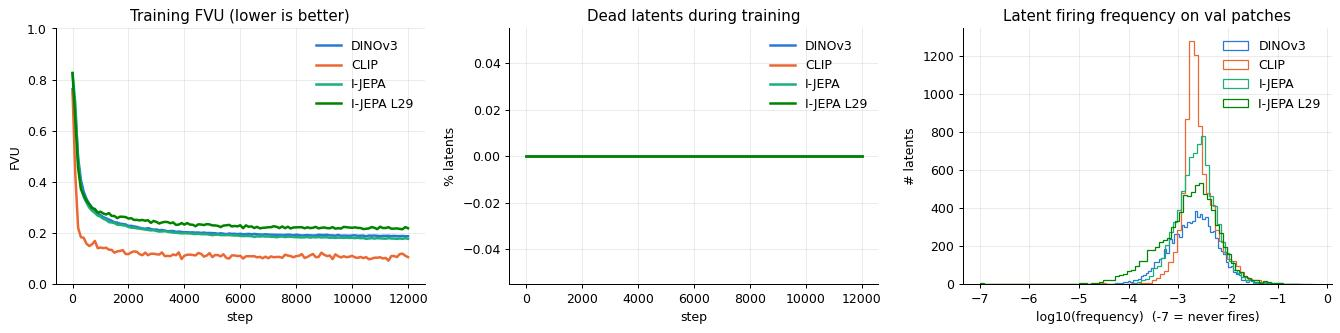

model      dim  val FVU    dead  probe mIoU raw  probe mIoU SAE
DINOv3     768    0.221    0.0%           0.542           0.540
CLIP       768    0.110    0.0%           0.418           0.378
I-JEPA    1280    0.193    0.0%           0.318           0.286
I-JEPA L29  1280    0.233    0.0%           0.339           0.308
control SAE on DINOv3: val FVU 0.221


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name, r in R.items():
    log = r['log']
    axes[0].plot(log[:, 0], log[:, 1], color=COLORS[name], lw=2, label=name)
    axes[1].plot(log[:, 0], 100 * log[:, 2], color=COLORS[name], lw=2, label=name)
    freq = torch.bincount(r['idx'][r['val'] > 0].long().flatten(), minlength=N_LATENTS).float() / r['idx'][..., 0].numel()
    r['freq'] = freq
    axes[2].hist(np.log10(freq.numpy() + 1e-7), bins=80, histtype='step', lw=2, color=COLORS[name], label=name)
axes[0].set(title='Training FVU (lower is better)', xlabel='step', ylabel='FVU', ylim=(0, 1))
axes[1].set(title='Dead latents during training', xlabel='step', ylabel='% latents')
axes[2].set(title='Latent firing frequency on val patches', xlabel='log10(frequency)  (-7 = never fires)', ylabel='# latents')
for ax in axes: ax.legend(frameon=False)
plt.tight_layout(); savefig('sae_training')

rows = []
for name, r in R.items():
    rows.append((name, r['D'], r['fvu'], (r['freq'] == 0).float().mean().item(),
                 r['probe_raw']['miou'], r['probe_sae']['miou']))
print(f"{'model':8s} {'dim':>5s} {'val FVU':>8s} {'dead':>7s} {'probe mIoU raw':>15s} {'probe mIoU SAE':>15s}")
for row in rows:
    print(f'{row[0]:8s} {row[1]:5d} {row[2]:8.3f} {row[3]:7.1%} {row[4]:15.3f} {row[5]:15.3f}')
print(f"control SAE on {CONTROL_MODEL}: val FVU {R[CONTROL_MODEL]['fvu_control']:.3f}")

### Token norms: register-like artifacts
ViTs trained without registers often produce a few **high-norm "artifact" tokens** in background regions
(Darcet et al., *Vision Transformers Need Registers*, 2024). DINOv3 has registers; CLIP and I-JEPA do not.
We mark a token as high-norm if its norm exceeds 3x the model's median token norm, and later check whether
SAE latents specialise on these tokens.

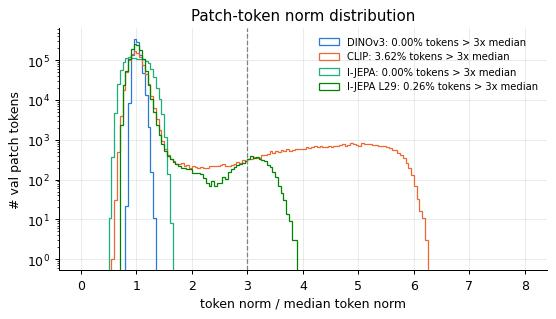

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, r in R.items():
    n = r['norms'].flatten()
    rel = (n / n.median()).numpy()
    r['outlier'] = (n > OUTLIER_FACTOR * n.median()).view_as(r['norms'])
    ax.hist(rel, bins=np.linspace(0, 8, 161), histtype='step', lw=2, color=COLORS[name],
            label=f"{name}: {r['outlier'].float().mean():.2%} tokens > {OUTLIER_FACTOR:g}x median")
ax.axvline(OUTLIER_FACTOR, color='gray', ls='--', lw=1)
ax.set(yscale='log', xlabel='token norm / median token norm', ylabel='# val patch tokens',
       title='Patch-token norm distribution')
ax.legend(frameon=False, fontsize=8)
savefig('token_norms')

## 5. What kind of concept is each latent?
For every latent we compute, over the ~1M val patches (activation-weighted):

* **purity**: share of its activation on its single most common COCO category;
* **super-purity**: the same at the level of COCO super-categories (animal, vehicle, food, ...);
* **background share**: share on patches not covered by any object ("stuff": sky, road, wall, grass, ...);
* **coverage**: for objects of its best category on which it fires, the fraction of the object's patches it covers
  (whole-object latents -> high, part latents -> low);
* **boundary share**: share on patches that straddle an object boundary;
* **position eta^2**: fraction of its activation variance explained by *where* in the image the patch is;
* **spread**: when it fires in an image, the fraction of that image's patches it fires on (global "gist" latents);
* **high-norm share**: share on artifact tokens (see above).

These give a rule-based taxonomy (thresholds in the table below; rules applied top to bottom).

In [12]:
TYPE_RULES = [  # (type, description)
    ('dead', 'never fires on val'),
    ('rare', f'< {MIN_COUNT} active val patches'),
    ('positional', f"position eta^2 >= {TH['positional']}"),
    ('artifact', f"high-norm share >= {TH['artifact']}"),
    ('global', f"spread >= {TH['spread']}"),
    ('boundary', f"boundary share >= {TH['boundary']}"),
    ('object', f"purity >= {TH['purity']} and coverage >= {TH['coverage']}"),
    ('part', f"purity >= {TH['purity']} and coverage < {TH['coverage']}"),
    ('super-category', f"super-purity >= {TH['super']} and background share < 0.3"),
    ('stuff', f"background share >= {TH['stuff']}  (base rate: {(LABELS[14]['cat'] == BG).float().mean():.0%} of patches)"),
    ('mixed', 'everything else'),
]
TYPES = [t for t, _ in TYPE_RULES]
TYPE_COLORS = {'object': '#2a78d6', 'part': '#1baf7a', 'super-category': '#008300', 'stuff': '#eb6834',
               'boundary': '#e87ba4', 'global': '#eda100', 'positional': '#4a3aa7', 'artifact': '#e34948',
               'mixed': '#c9c8c2', 'rare': '#8f8e89', 'dead': '#52514e'}


@torch.no_grad()
def latent_stats(name, tag=''):
    r = R[name]
    g = r['grid']; P = g * g
    lab = LABELS[g]
    idx = r[f'idx{tag}'].to(DEV).long().flatten()
    val = r[f'val{tag}'].to(DEV).float().flatten()
    T = r[f'idx{tag}'].shape[0] * P
    N = T // P
    tok = torch.arange(T, device=DEV).repeat_interleave(TOPK)
    keep = val > 0
    idx, val, tok = idx[keep], val[keep], tok[keep]
    cat = lab['cat'].to(DEV).flatten()[tok]
    inst = lab['inst'].to(DEV).flatten()[tok]
    bnd = lab['boundary'].to(DEV).flatten()[tok].float()
    outl = r['outlier'].to(DEV).flatten()[tok].float()
    n = N_LATENTS
    zeros = lambda: torch.zeros(n, device=DEV)

    count = torch.bincount(idx, minlength=n).float()
    mass = zeros().index_add_(0, idx, val)
    safe = mass.clamp_min(1e-9)
    H = torch.zeros(n * 81, device=DEV).index_add_(0, idx * 81 + cat, val).view(n, 81)       # activation mass
    C = torch.bincount(idx * 81 + cat, minlength=n * 81).float().view(n, 81)                  # counts
    best = H[:, :80].argmax(1)
    purity = H.gather(1, best[:, None])[:, 0] / safe
    Hs = torch.zeros(n, len(SUPERS), device=DEV).index_add_(1, CAT_SUPER.to(DEV), H[:, :80])
    super_purity = Hs.max(1).values / safe
    bg_share = H[:, BG] / safe

    # part vs whole: coverage of objects of the latent's best category
    inst_size = torch.bincount(lab['inst'].flatten().clamp_min(0).to(DEV),
                               weights=(lab['inst'].flatten() >= 0).float().to(DEV), minlength=lab['n_inst'])
    sel = (inst >= 0) & (cat == best[idx])
    sel &= inst_size[inst.clamp_min(0)] >= MIN_INST_PATCHES
    uk, cnt = torch.unique(idx[sel] * lab['n_inst'] + inst[sel], return_counts=True)
    lat = uk // lab['n_inst']
    cov = (cnt.float() / inst_size[uk % lab['n_inst']]).clamp(max=1)
    n_obj = torch.bincount(lat, minlength=n).float()
    coverage = zeros().index_add_(0, lat, cov) / n_obj                                      # nan if no objects

    # spread within images
    uk, cnt = torch.unique(idx * N + tok // P, return_counts=True)
    spread = zeros().index_add_(0, uk // N, cnt.float() / P) / torch.bincount(uk // N, minlength=n).float().clamp_min(1)

    # positional eta^2
    S = torch.zeros(n * P, device=DEV).index_add_(0, idx * P + tok % P, val).view(n, P)
    sumsq = zeros().index_add_(0, idx, val ** 2)
    m_all = mass / T
    between = N * ((S / N - m_all[:, None]) ** 2).sum(1)
    eta2 = between / (sumsq - T * m_all ** 2).clamp_min(1e-9)

    st = dict(count=count, freq=count / T, purity=purity, super_purity=super_purity, bg_share=bg_share,
              coverage=coverage, n_obj=n_obj, spread=spread, eta2=eta2,
              boundary_share=zeros().index_add_(0, idx, val * bnd) / safe,
              outlier_share=zeros().index_add_(0, idx, val * outl) / safe, best_cat=best)
    st = {k: v.cpu() for k, v in st.items()}
    st['C'] = C.cpu()

    cov_f = torch.nan_to_num(st['coverage'], nan=1.0)  # only tiny objects -> treat as whole
    rules = [
        ('dead', st['count'] == 0),
        ('rare', st['count'] < MIN_COUNT),
        ('positional', st['eta2'] >= TH['positional']),
        ('artifact', st['outlier_share'] >= TH['artifact']),
        ('global', st['spread'] >= TH['spread']),
        ('boundary', st['boundary_share'] >= TH['boundary']),
        ('object', (st['purity'] >= TH['purity']) & (cov_f >= TH['coverage'])),
        ('part', st['purity'] >= TH['purity']),
        ('super-category', (st['super_purity'] >= TH['super']) & (st['bg_share'] < 0.3)),
        ('stuff', st['bg_share'] >= TH['stuff']),
    ]
    types = np.array(['mixed'] * n, dtype=object)
    done = np.zeros(n, bool)
    for t_, m in rules:
        m = m.numpy() & ~done
        types[m] = t_; done |= m
    st['type'] = types
    return st


ST = {name: latent_stats(name) for name in R}
ST_CONTROL = latent_stats(CONTROL_MODEL, '_control')

def auto_label(name, j, st=None):
    s = (st or ST[name])
    t = s['type'][j]
    if t in ('object', 'part', 'boundary'):
        return f"{t}: {CAT_NAMES[s['best_cat'][j]]} ({s['purity'][j]:.0%})"
    if t == 'super-category':
        sup = SUPERS[int(CAT_SUPER[s['best_cat'][j]])]
        return f"super: {sup} ({s['super_purity'][j]:.0%})"
    if t == 'stuff':
        return f"stuff / background ({s['bg_share'][j]:.0%})"
    return t

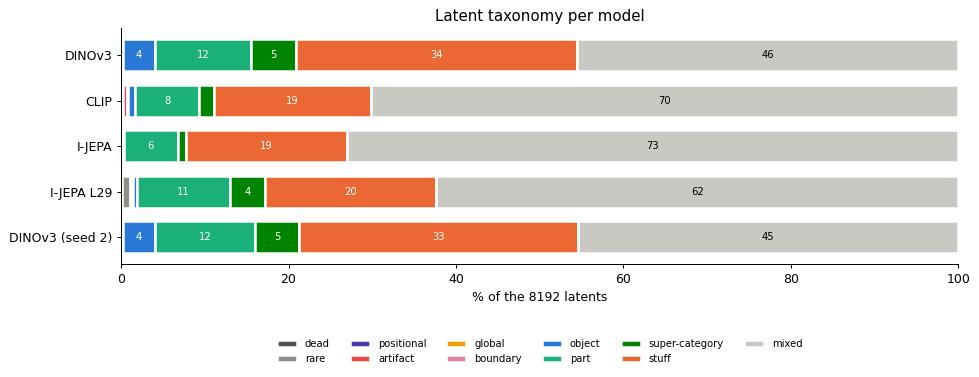

type                      DINOv3             CLIP           I-JEPA       I-JEPA L29  DINOv3 (seed 2)   rule
dead                           0                1                1                4                0   never fires on val
rare                           2               22                2               78                8   < 50 active val patches
positional                     8                0               10               19                8   position eta^2 >= 0.3
artifact                       0               39                0               14                0   high-norm share >= 0.5
global                         0                1                0                0                1   spread >= 0.5
boundary                       6                2                1                4                5   boundary share >= 0.6
object                       313               71               13               32              308   purity >= 0.5 and coverage >= 0.5
part         

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.4))
names = list(R) + [f'{CONTROL_MODEL} (seed 2)']
all_types = [ST[n]['type'] for n in R] + [ST_CONTROL['type']]
for row, types in enumerate(all_types):
    left = 0
    for t_ in TYPES:
        w = 100 * np.mean(types == t_)
        ax.barh(row, w, left=left, color=TYPE_COLORS[t_], edgecolor='white', linewidth=2, height=0.7,
                label=t_ if row == 0 else None)
        if w >= 3.5:
            ax.text(left + w / 2, row, f'{w:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if t_ not in ('mixed', 'global') else 'black')
        left += w
ax.set_yticks(range(len(names)), names); ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel='% of the 8192 latents', title='Latent taxonomy per model')
ax.grid(False)
ax.legend(ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.28), loc='upper center', fontsize=8)
savefig('taxonomy')

print(f"{'type':15s}" + ''.join(f'{n:>17s}' for n in names) + '   rule')
for (t_, desc) in TYPE_RULES:
    print(f'{t_:15s}' + ''.join(f'{np.sum(ty == t_):17d}' for ty in all_types) + f'   {desc}')

The thresholds above are a choice, so we also compare the **full distributions** of each metric over live latents
(active on >= MIN_COUNT val patches). Curves further right = more of that property.

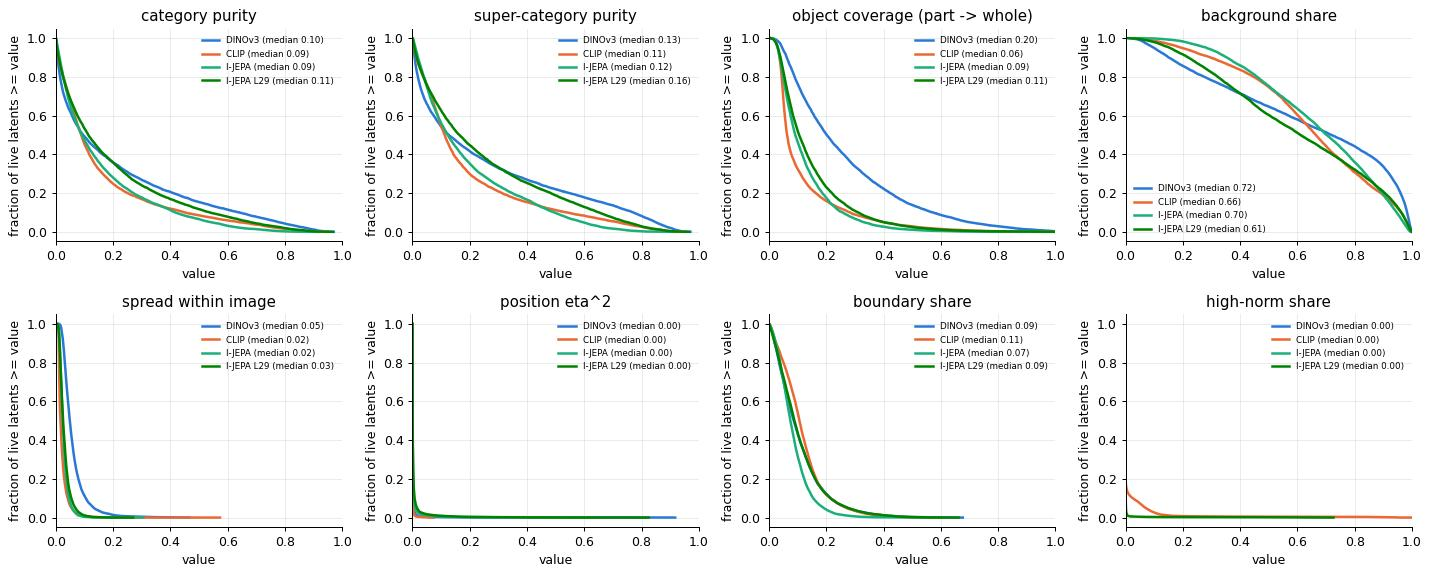

In [14]:
metrics = [('purity', 'category purity'), ('super_purity', 'super-category purity'),
           ('coverage', 'object coverage (part -> whole)'), ('bg_share', 'background share'),
           ('spread', 'spread within image'), ('eta2', 'position eta^2'),
           ('boundary_share', 'boundary share'), ('outlier_share', 'high-norm share')]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, (key, title) in zip(axes.flat, metrics):
    for name in R:
        live = ST[name]['count'] >= MIN_COUNT
        x = ST[name][key][live].numpy()
        x = np.sort(x[~np.isnan(x)])
        ax.plot(x, 1 - np.arange(len(x)) / len(x), color=COLORS[name], lw=2, label=f'{name} (median {np.median(x):.2f})')
    ax.set(title=title, xlabel='value', ylabel='fraction of live latents >= value', xlim=(0, 1))
    ax.legend(frameon=False, fontsize=7)
plt.tight_layout(); savefig('metric_distributions')

### Object-level concepts: is there a dedicated latent for each COCO category?
For each category and model we find the single latent whose firing pattern best segments that category at the
patch level (binary F1 between "latent active" and "patch belongs to category"). A high score means the model's
dictionary contains a clean, dedicated concept for that object class.

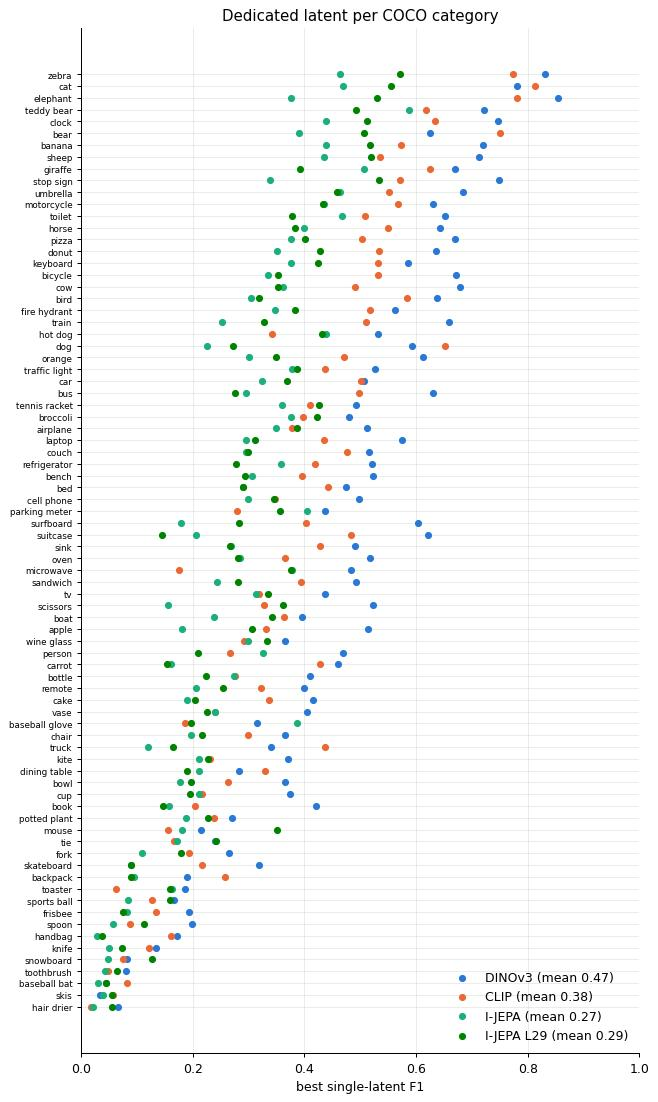

categories with a dedicated latent (F1 >= 0.3): DINOv3: 63/80, CLIP: 51/80, I-JEPA: 35/80, I-JEPA L29: 39/80
categories with a dedicated latent (F1 >= 0.5): DINOv3: 38/80, CLIP: 23/80, I-JEPA: 2/80, I-JEPA L29: 8/80
background best F1: DINOv3: 0.57, CLIP: 0.64, I-JEPA: 0.38, I-JEPA L29: 0.43


In [15]:
cat_tot = {g: torch.bincount(LABELS[g]['cat'].flatten(), minlength=81).float() for g in GRIDS}
BEST_F1 = {}
for name in R:
    C, cnt = ST[name]['C'], ST[name]['count']
    prec = C / cnt[:, None].clamp_min(1)
    rec = C / cat_tot[R[name]['grid']][None].clamp_min(1)
    f1 = 2 * prec * rec / (prec + rec).clamp_min(1e-9)
    BEST_F1[name] = f1.max(0)   # values & latent index per category (81)

present = [c for c in range(80) if cat_tot[14][c] >= 20]
order = sorted(present, key=lambda c: -np.mean([BEST_F1[n].values[c].item() for n in R]))
fig, ax = plt.subplots(figsize=(8, 0.17 * len(order) + 1.2))
for name in R:
    ax.scatter([BEST_F1[name].values[c].item() for c in order], range(len(order)), s=22, color=COLORS[name],
               label=f'{name} (mean {np.mean([BEST_F1[name].values[c].item() for c in present]):.2f})', zorder=3)
ax.set_yticks(range(len(order)), [CAT_NAMES[c] for c in order], fontsize=7)
ax.invert_yaxis()
ax.set(xlabel='best single-latent F1', title='Dedicated latent per COCO category', xlim=(0, 1))
ax.legend(frameon=False, loc='lower right')
savefig('category_f1')

for thr in (0.3, 0.5):
    print(f'categories with a dedicated latent (F1 >= {thr}): ' +
          ', '.join(f"{n}: {int(sum(BEST_F1[n].values[c] >= thr for c in present))}/{len(present)}" for n in R))
print('background best F1: ' + ', '.join(f"{n}: {BEST_F1[n].values[BG]:.2f}" for n in R))

## 6. Which concepts are shared across models?
We place every model's latent activations on the same 14x14 patch grid (I-JEPA's 16x16 maps are area-resampled)
and compute the Pearson correlation between **every pair of latents** across models over all val patches
(3 x 8192 x 8192 correlations). For each latent, its best match in another model tells us whether that model has
the "same" concept. As a calibration, we do the same between two SAEs trained with different seeds on the *same*
DINOv3 features: that is roughly the best agreement one can expect.

In [16]:
CODES = {name: dict(idx=R[name]['idx'], val=R[name]['val'], grid=R[name]['grid']) for name in R}
CODES['control'] = dict(idx=R[CONTROL_MODEL]['idx_control'], val=R[CONTROL_MODEL]['val_control'],
                        grid=R[CONTROL_MODEL]['grid'])

@torch.no_grad()
def dense_codes(key, b):
    c = CODES[key]; g = c['grid']
    i = c['idx'][b].to(DEV).long().view(-1, TOPK)
    v = c['val'][b].to(DEV).float().view(-1, TOPK)
    z = torch.zeros(len(i), N_LATENTS, device=DEV).scatter(1, i, v)
    if g != 14:
        z = F.adaptive_avg_pool2d(z.view(len(b), g, g, -1).permute(0, 3, 1, 2), 14).permute(0, 2, 3, 1)
    return z.reshape(-1, N_LATENTS)

@torch.no_grad()
def cross_correlations(pairs, bs=24):
    keys = sorted({k for p in pairs for k in p})
    s = {k: torch.zeros(N_LATENTS, device=DEV, dtype=torch.float64) for k in keys}
    ss = {k: torch.zeros(N_LATENTS, device=DEV, dtype=torch.float64) for k in keys}
    cross = {p: torch.zeros(N_LATENTS, N_LATENTS, device=DEV) for p in pairs}
    T = 0
    for b in torch.arange(N_VAL_IMAGES).split(bs):
        z = {k: dense_codes(k, b) for k in keys}
        for k in keys:
            s[k] += z[k].sum(0).double(); ss[k] += (z[k] ** 2).sum(0).double()
        for a, c in pairs:
            cross[(a, c)] += z[a].T @ z[c]
        T += len(b) * 196
        del z
    out = {}
    for a, c in pairs:
        ma, mc = s[a] / T, s[c] / T
        sa = (ss[a] / T - ma ** 2).clamp_min(0).sqrt(); sc = (ss[c] / T - mc ** 2).clamp_min(0).sqrt()
        cov = cross[(a, c)].double() / T - ma[:, None] * mc[None]
        corr = cov / (sa[:, None] * sc[None]).clamp_min(1e-12)
        corr[(sa == 0)[:, None] | (sc == 0)[None]] = 0
        out[(a, c)] = corr.float().cpu()
        del cov, corr
    return out

t = time.time()
names = MAIN
PAIRS = [(names[0], names[1]), (names[0], names[2]), (names[1], names[2]), (CONTROL_MODEL, 'control'),
         (names[0], IJ_MID), (names[1], IJ_MID)]
CORR = cross_correlations(PAIRS)
torch.cuda.empty_cache()
print(f'cross-correlations: {time.time() - t:.0f}s')

def best_match(a, c):
    """For each latent of a: (best corr, index) in c."""
    if (a, c) in CORR: m = CORR[(a, c)]
    else: m = CORR[(c, a)].T
    return m.max(1)

MAXC = {(a, c): best_match(a, c) for a in names for c in names if a != c}
MAXC[(CONTROL_MODEL, 'control')] = best_match(CONTROL_MODEL, 'control')
for a in names[:2]:
    MAXC[(a, IJ_MID)] = best_match(a, IJ_MID)

cross-correlations: 142s


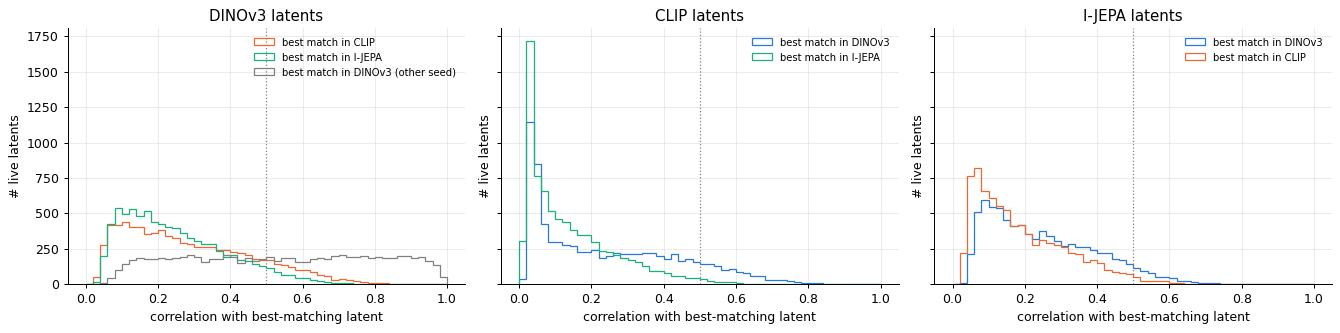

 DINOv3 -> CLIP    : median best corr 0.25, 14% of live latents >= 0.5, 765 mutual-best pairs
 DINOv3 -> I-JEPA  : median best corr 0.22, 6% of live latents >= 0.5, 338 mutual-best pairs
   CLIP -> I-JEPA  : median best corr 0.11, 2% of live latents >= 0.5, 107 mutual-best pairs


 DINOv3 -> control : median best corr 0.54, 54% of live latents >= 0.5, 3410 mutual-best pairs


 DINOv3 -> I-JEPA L29: median best corr 0.26, 12% of live latents >= 0.5, 661 mutual-best pairs


   CLIP -> I-JEPA L29: median best corr 0.12, 3% of live latents >= 0.5, 198 mutual-best pairs


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, a in zip(axes, names):
    live = ST[a]['count'] >= MIN_COUNT
    for c in names:
        if c == a: continue
        x = MAXC[(a, c)].values[live].numpy()
        ax.hist(x, bins=np.linspace(0, 1, 51), histtype='step', lw=2, color=COLORS[c], label=f'best match in {c}')
    if a == CONTROL_MODEL:
        x = MAXC[(a, 'control')].values[live].numpy()
        ax.hist(x, bins=np.linspace(0, 1, 51), histtype='step', lw=2, ls='--', color='gray',
                label=f'best match in {a} (other seed)')
    ax.axvline(SHARED_CORR, color='gray', lw=1, ls=':')
    ax.set(title=f'{a} latents', xlabel='correlation with best-matching latent', ylabel='# live latents')
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); savefig('best_match_hist')

for (a, c) in PAIRS:
    fw = MAXC[(a, c)]; bw = MAXC[(c, a)] if (c, a) in MAXC else best_match(c, a)
    mutual = (bw.indices[fw.indices] == torch.arange(N_LATENTS)) & (fw.values >= SHARED_CORR)
    live = ST[a]['count'] >= MIN_COUNT
    print(f'{a:>7s} -> {c:<8s}: median best corr {fw.values[live].median():.2f}, '
          f'{(fw.values[live] >= SHARED_CORR).float().mean():.0%} of live latents >= {SHARED_CORR}, '
          f'{int(mutual.sum())} mutual-best pairs')

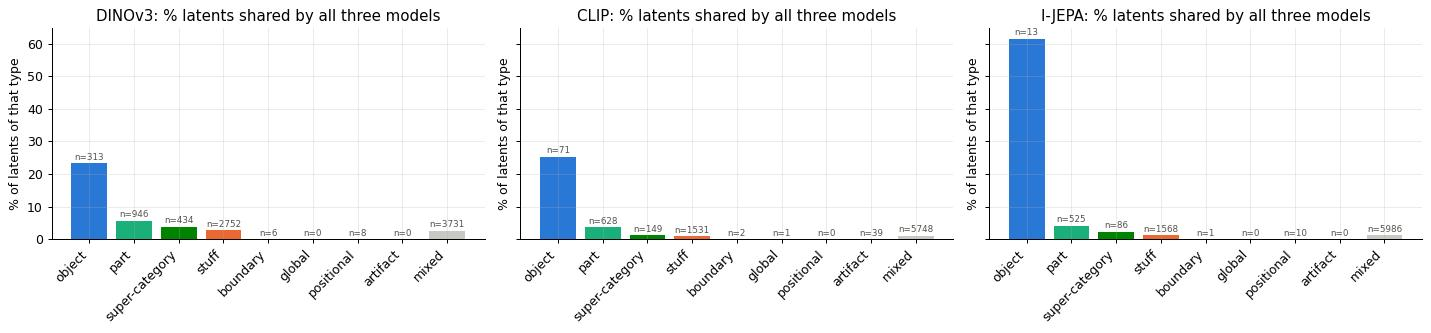

DINOv3 : +CLIP: 10%, +I-JEPA: 2%, all three: 4%, unique: 83%
CLIP   : +DINOv3: 12%, +I-JEPA: 0%, all three: 2%, unique: 87%
I-JEPA : +CLIP: 1%, +DINOv3: 5%, all three: 2%, unique: 93%


In [18]:
SHARE = {}
for a in names:
    o1, o2 = [c for c in names if c != a]
    s1, s2 = (MAXC[(a, o1)].values >= SHARED_CORR).numpy(), (MAXC[(a, o2)].values >= SHARED_CORR).numpy()
    cls = np.where(s1 & s2, 'all three', np.where(s1, f'+{o1}', np.where(s2, f'+{o2}', 'unique')))
    SHARE[a] = cls

type_order = ['object', 'part', 'super-category', 'stuff', 'boundary', 'global', 'positional', 'artifact', 'mixed']
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, a in zip(axes, names):
    frac = [np.mean(SHARE[a][ST[a]['type'] == t_] == 'all three') if np.any(ST[a]['type'] == t_) else 0
            for t_ in type_order]
    nums = [np.sum(ST[a]['type'] == t_) for t_ in type_order]
    ax.bar(range(len(type_order)), 100 * np.array(frac), color=[TYPE_COLORS[t_] for t_ in type_order])
    for k, (f_, n_) in enumerate(zip(frac, nums)):
        ax.text(k, 100 * f_ + 1, f'n={n_}', ha='center', fontsize=7, color='#52514e')
    ax.set_xticks(range(len(type_order)), type_order, rotation=45, ha='right')
    ax.set(title=f'{a}: % latents shared by all three models', ylabel='% of latents of that type')
plt.tight_layout(); savefig('shared_by_type')

for a in names:
    live = ST[a]['count'] >= MIN_COUNT
    u, c = np.unique(SHARE[a][live.numpy()], return_counts=True)
    print(f'{a:7s}: ' + ', '.join(f'{k}: {v / live.sum():.0%}' for k, v in zip(u, c)))

## 7. Feature visualisations
Each row is one SAE latent; each column is one of its top-activating val images. The image is dimmed except where
the latent fires (upsampled patch activations). Row labels are the automatic labels from section 5.

In [19]:
IDX_D = {k: CODES[k]['idx'].to(DEV) for k in CODES}
VAL_D = {k: CODES[k]['val'].to(DEV) for k in CODES}

@torch.no_grad()
def top_images(key, j, n=6):
    score = torch.where(IDX_D[key] == j, VAL_D[key].float(), 0).amax((1, 2))
    return score.topk(n).indices.cpu().tolist()

def act_map(key, j, img):
    c = CODES[key]; g = c['grid']
    a = torch.where(c['idx'][img].long() == j, c['val'][img].float(), 0).sum(-1)
    return a.view(g, g)

def spotlight(ax, img, amap=None, vmax=None):
    im = VAL_IMGS[img].float() / 255
    if amap is not None:
        a = F.interpolate(amap[None, None], size=(IMG, IMG), mode='bilinear', align_corners=False)[0, 0]
        a = (a / (vmax or a.max().clamp_min(1e-6))).clamp(0, 1)
        im = im * (0.18 + 0.82 * a[..., None])
    ax.imshow(im.numpy()); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

def gallery(key, latents, title, n=6, labels=None, fname=None):
    fig, axes = plt.subplots(len(latents), n, figsize=(1.6 * n + 2.2, 1.6 * len(latents)), squeeze=False)
    for row, j in enumerate(latents):
        imgs = top_images(key, j, n)
        vmax = max(act_map(key, j, i).max().item() for i in imgs)
        for col, i in enumerate(imgs):
            spotlight(axes[row, col], i, act_map(key, j, i), vmax)
        lab = labels[row] if labels else f'#{j}\n{auto_label(key, j)}'
        axes[row, 0].set_ylabel(lab, rotation=0, ha='right', va='center', fontsize=8, labelpad=8)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(pad=0.3)
    if fname: savefig(fname)
    else: plt.show()

def pick(name, t_, n=4, key='count'):
    """Most frequent latents of a type (optionally sorted by another stat)."""
    cand = np.where(ST[name]['type'] == t_)[0]
    score = ST[name][key][cand].numpy()
    return cand[np.argsort(-score)[:n]].tolist()

### A tour of each model's dictionary
For each model: the most frequent whole-object, part, stuff and positional latents.

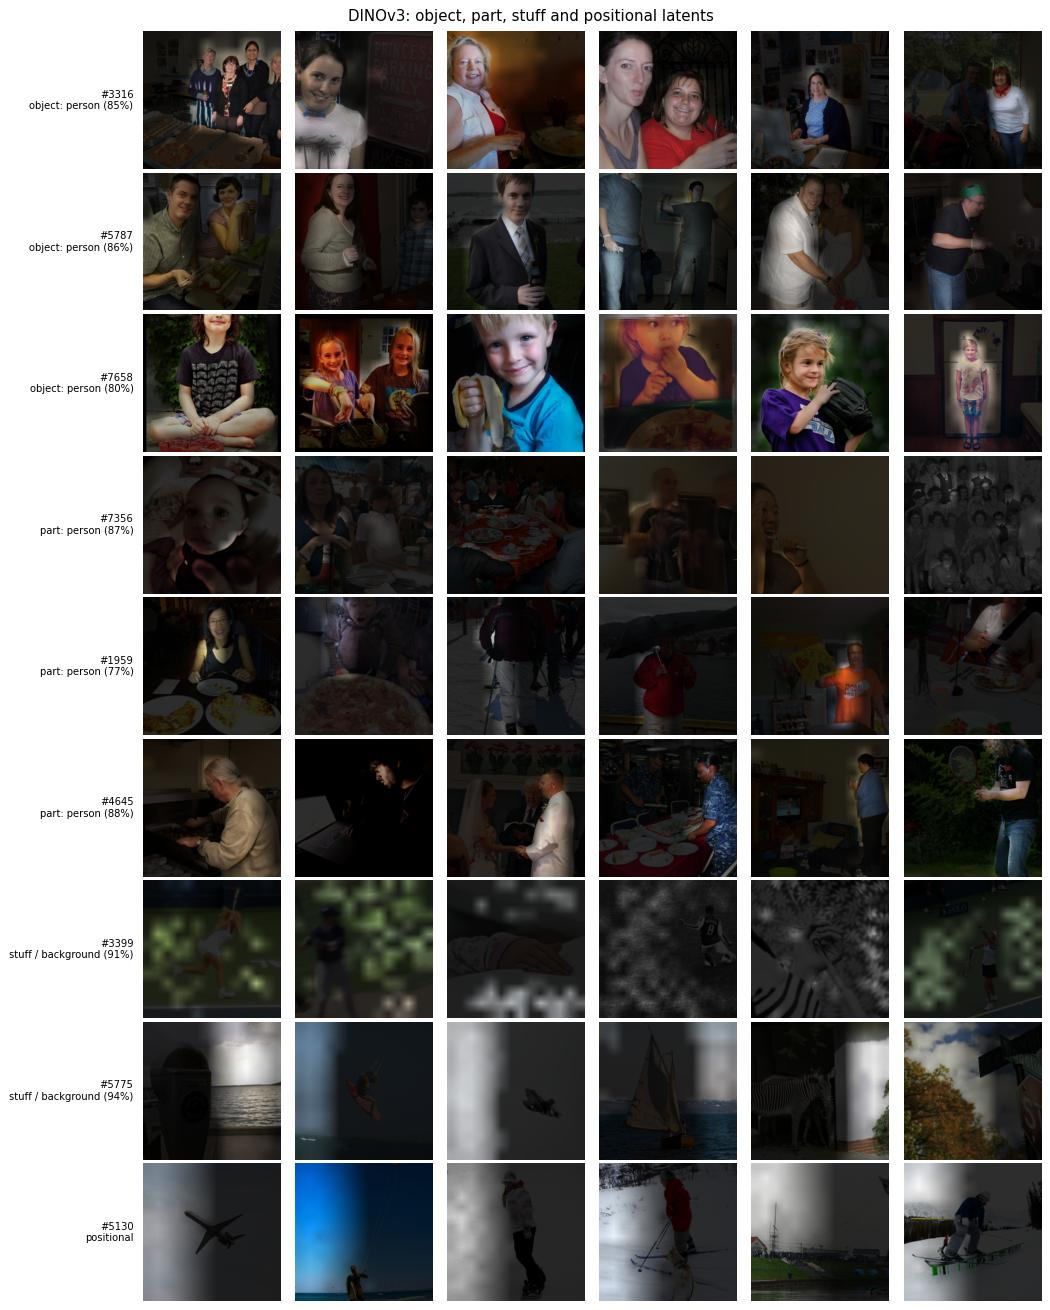

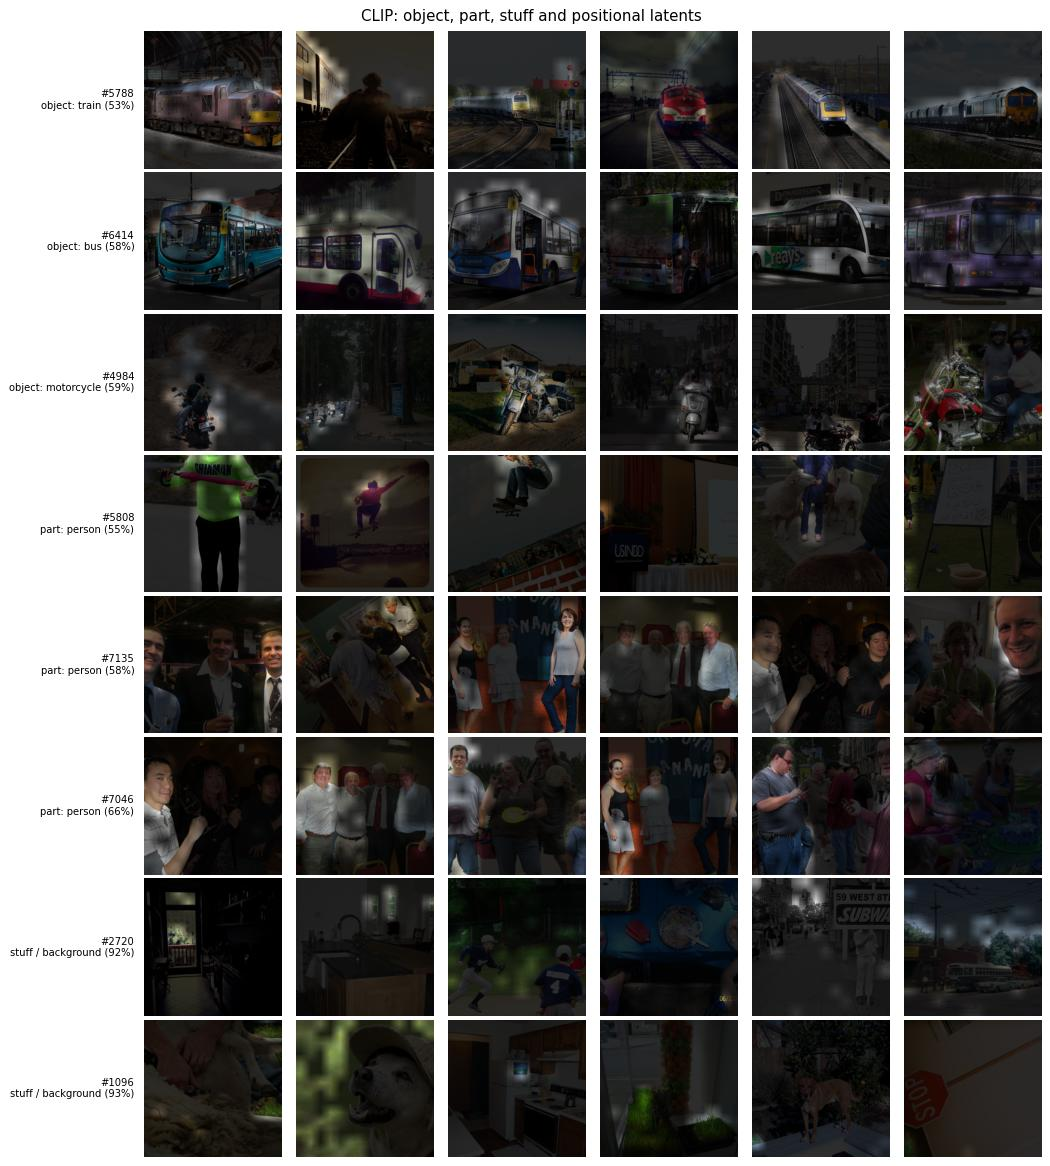

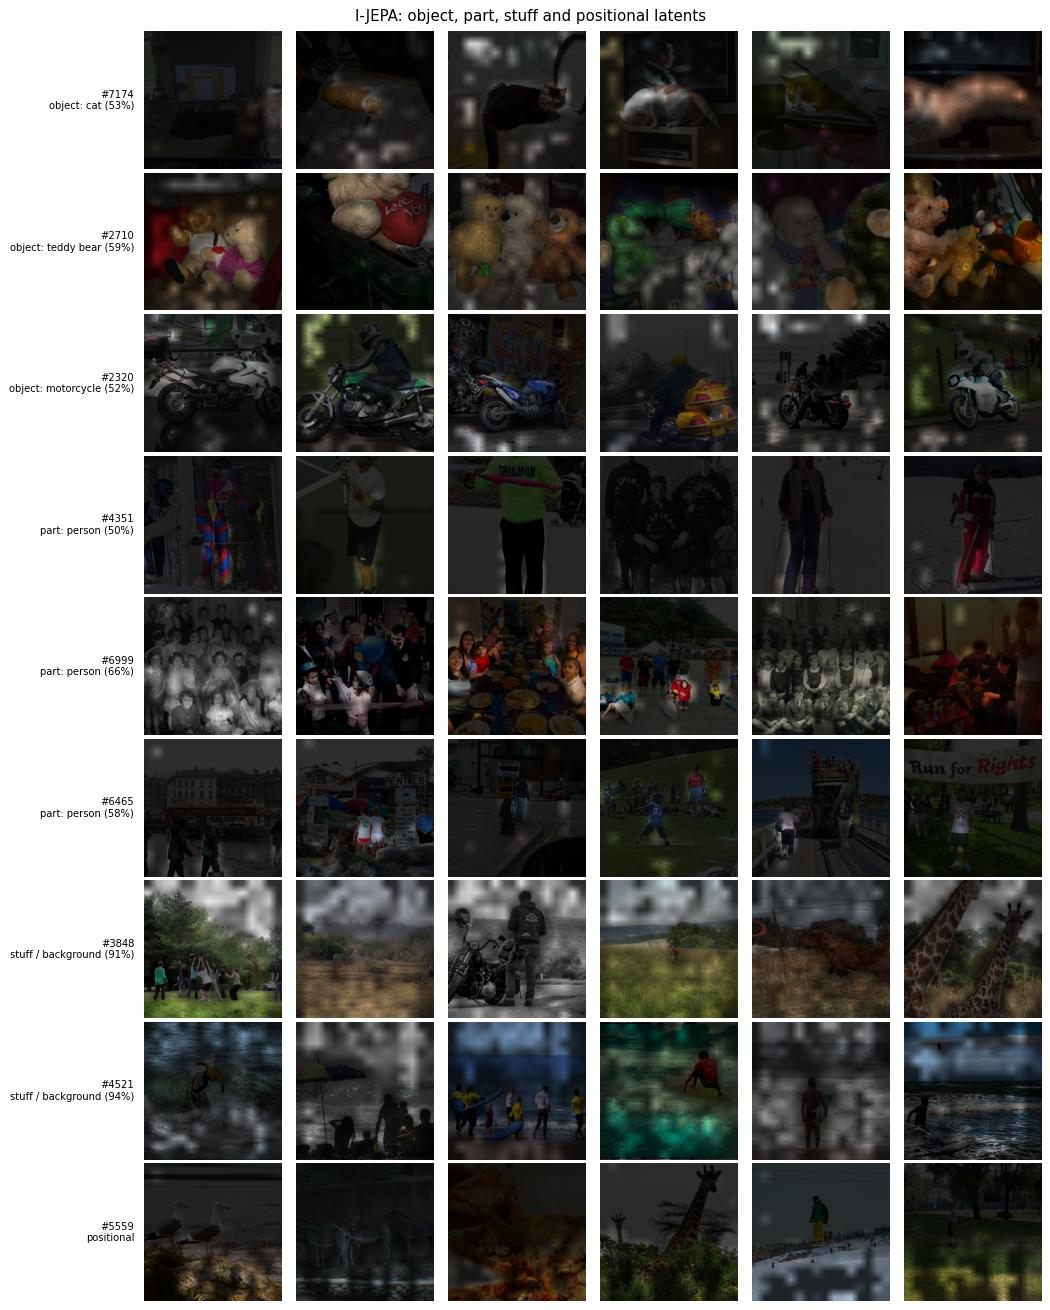

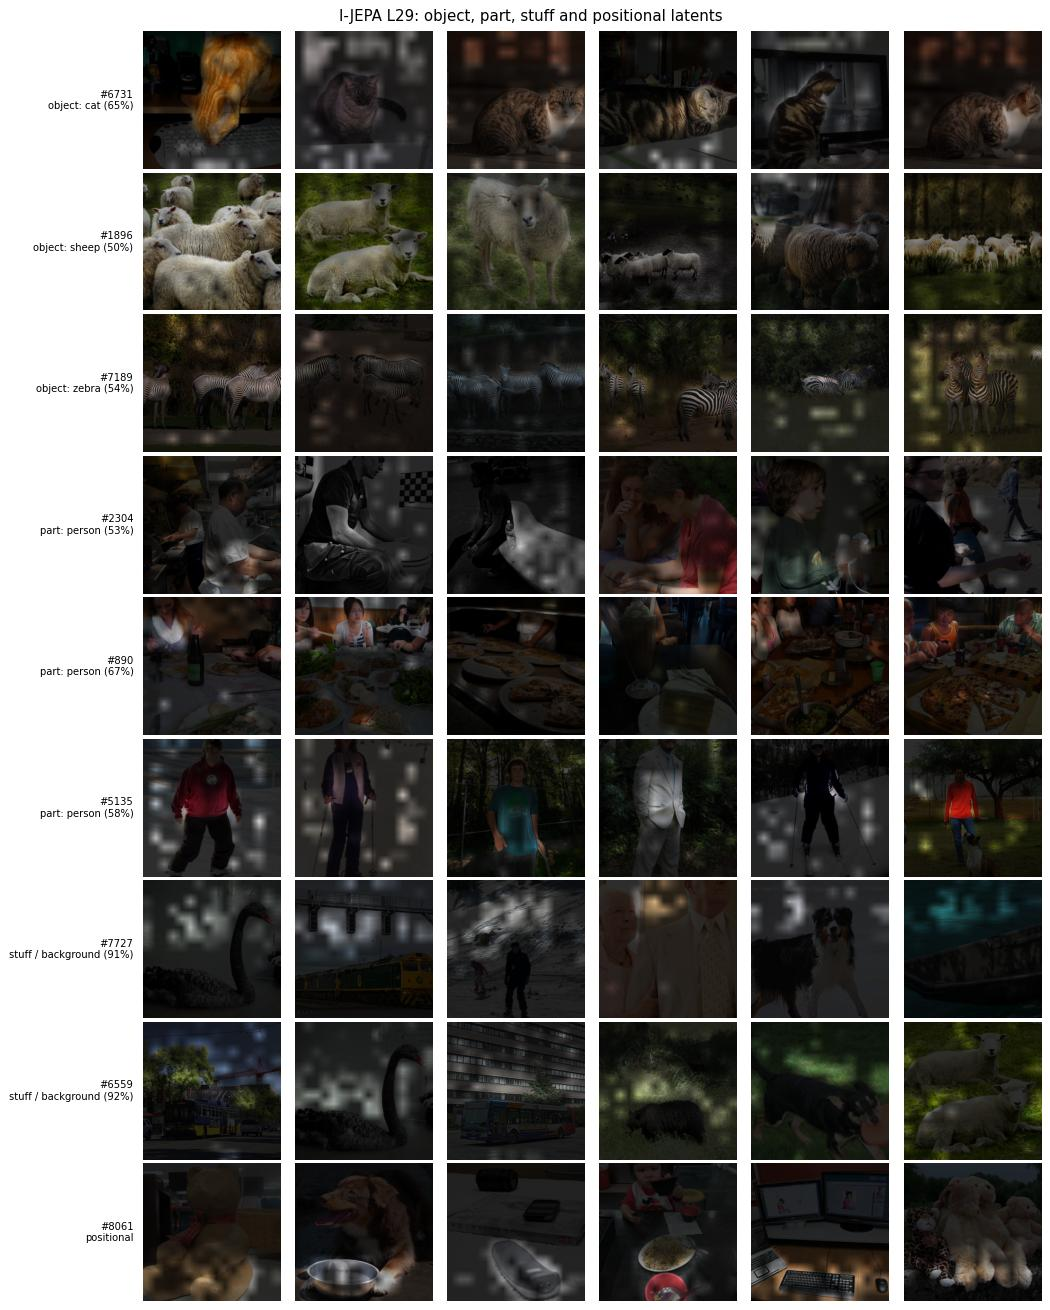

In [20]:
for name in ALL:
    lat = pick(name, 'object', 3) + pick(name, 'part', 3) + pick(name, 'stuff', 2) + pick(name, 'positional', 1)
    gallery(name, lat, f'{name}: object, part, stuff and positional latents',
            fname=f'tour_{name}')

### The same category through three dictionaries
For a few COCO categories, the best-F1 latent of each model (rows) on that latent's own top images.

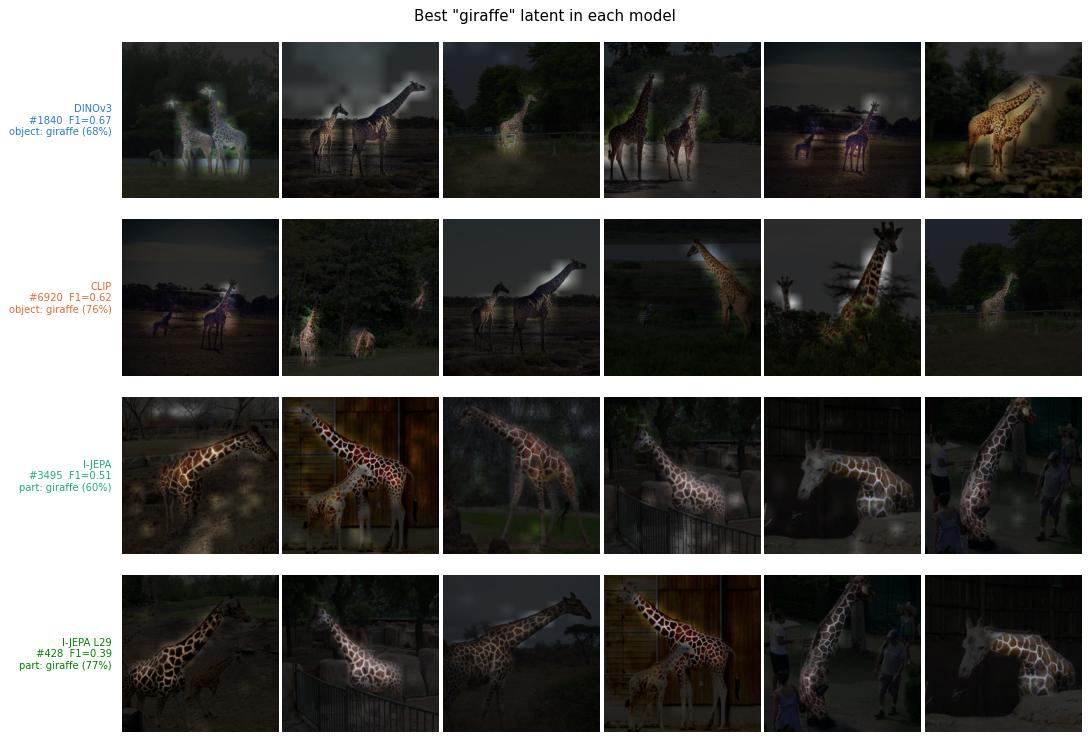

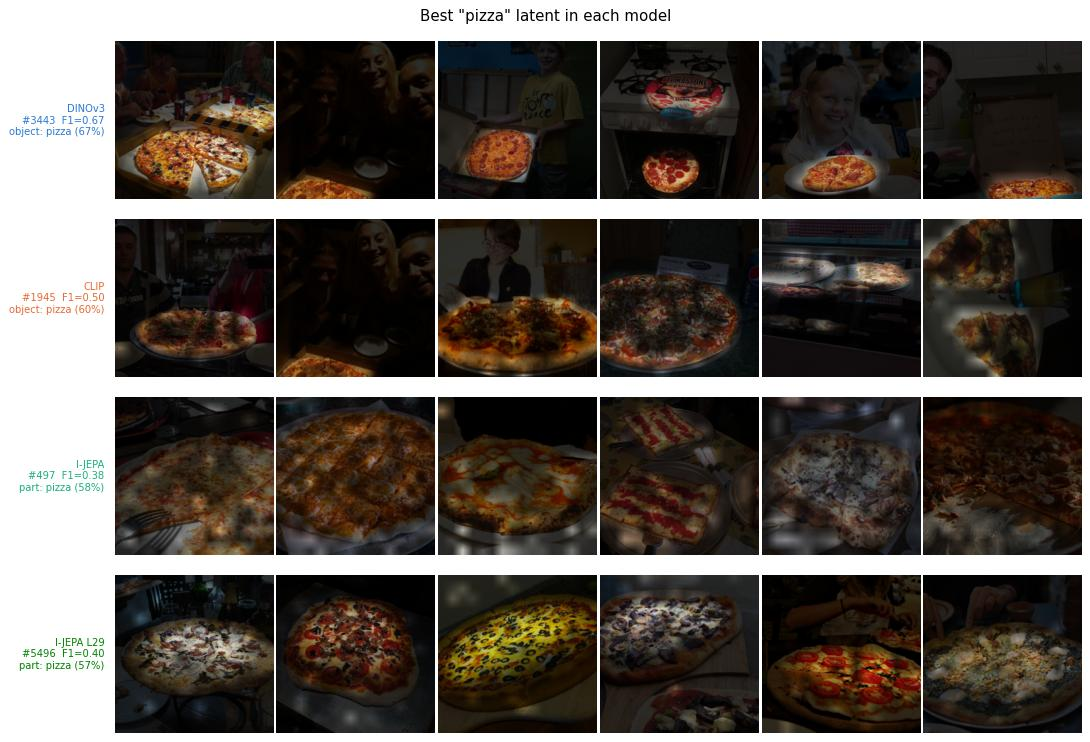

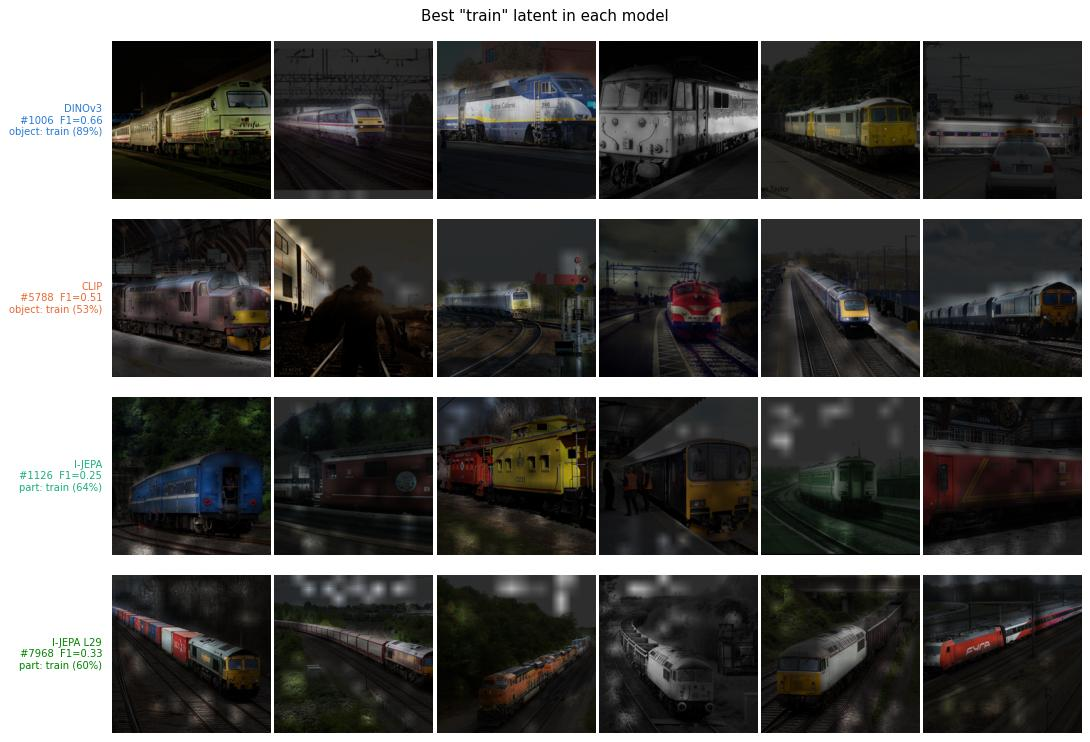

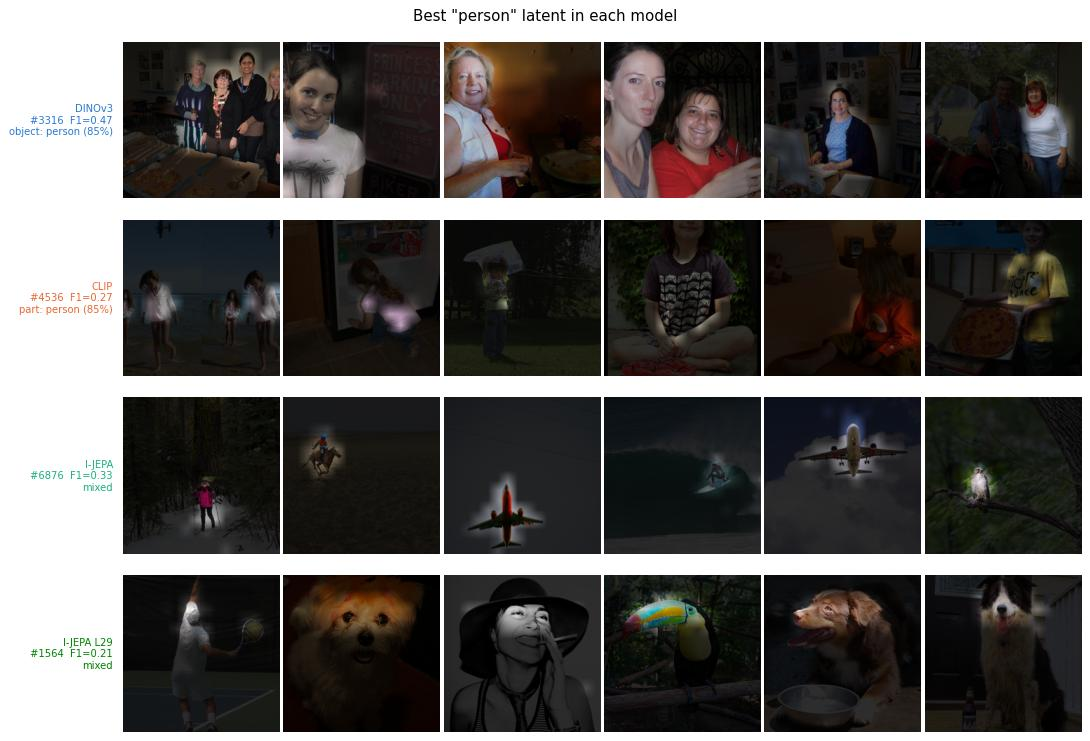

In [21]:
show_cats = [c for c in ['giraffe', 'pizza', 'train', 'person', 'cat', 'airplane'] if CAT_NAMES.index(c) in present][:4]
for cname in show_cats:
    c = CAT_NAMES.index(cname)
    lat = {n: BEST_F1[n].indices[c].item() for n in ALL}
    fig, axes = plt.subplots(len(ALL), 6, figsize=(12, 2.05 * len(ALL)))
    for row, n in enumerate(ALL):
        j = lat[n]
        imgs = top_images(n, j, 6)
        vmax = max(act_map(n, j, i).max().item() for i in imgs)
        for col, i in enumerate(imgs):
            spotlight(axes[row, col], i, act_map(n, j, i), vmax)
        axes[row, 0].set_ylabel(f'{n}\n#{j}  F1={BEST_F1[n].values[c]:.2f}\n{auto_label(n, j)}',
                                rotation=0, ha='right', va='center', fontsize=8, labelpad=8, color=COLORS[n])
    fig.suptitle(f'Best "{cname}" latent in each model', y=1.0)
    plt.tight_layout(pad=0.3)
    savefig(f'category_{cname}')

### Universal concepts: latent triplets shared by all three models
We start from DINOv3 latents, take their best match in CLIP and in I-JEPA, and score the triplet by its weakest
pairwise correlation. Rows show the three latents **on the same images** (the DINOv3 latent's top images),
so matching heatmaps mean the three models carved out the same concept. Positional latents are excluded
(they are trivially shared and shown separately).

top triplets (DINOv3, CLIP, I-JEPA) and min pairwise corr:
(1463, 3, 4731) 0.78 | stuff / background (96%) / mixed / mixed
(5182, 7903, 3891) 0.74 | mixed / mixed / mixed
(5346, 1705, 5099) 0.74 | stuff / background (92%) / mixed / stuff / background (91%)
(7559, 7769, 2135) 0.69 | mixed / mixed / mixed
(3564, 4226, 3870) 0.69 | mixed / mixed / mixed
(7831, 8016, 3870) 0.67 | mixed / mixed / mixed
(2226, 3990, 262) 0.66 | stuff / background (98%) / stuff / background (93%) / stuff / background (93%)
(7415, 2007, 189) 0.65 | mixed / part: stop sign (89%) / mixed


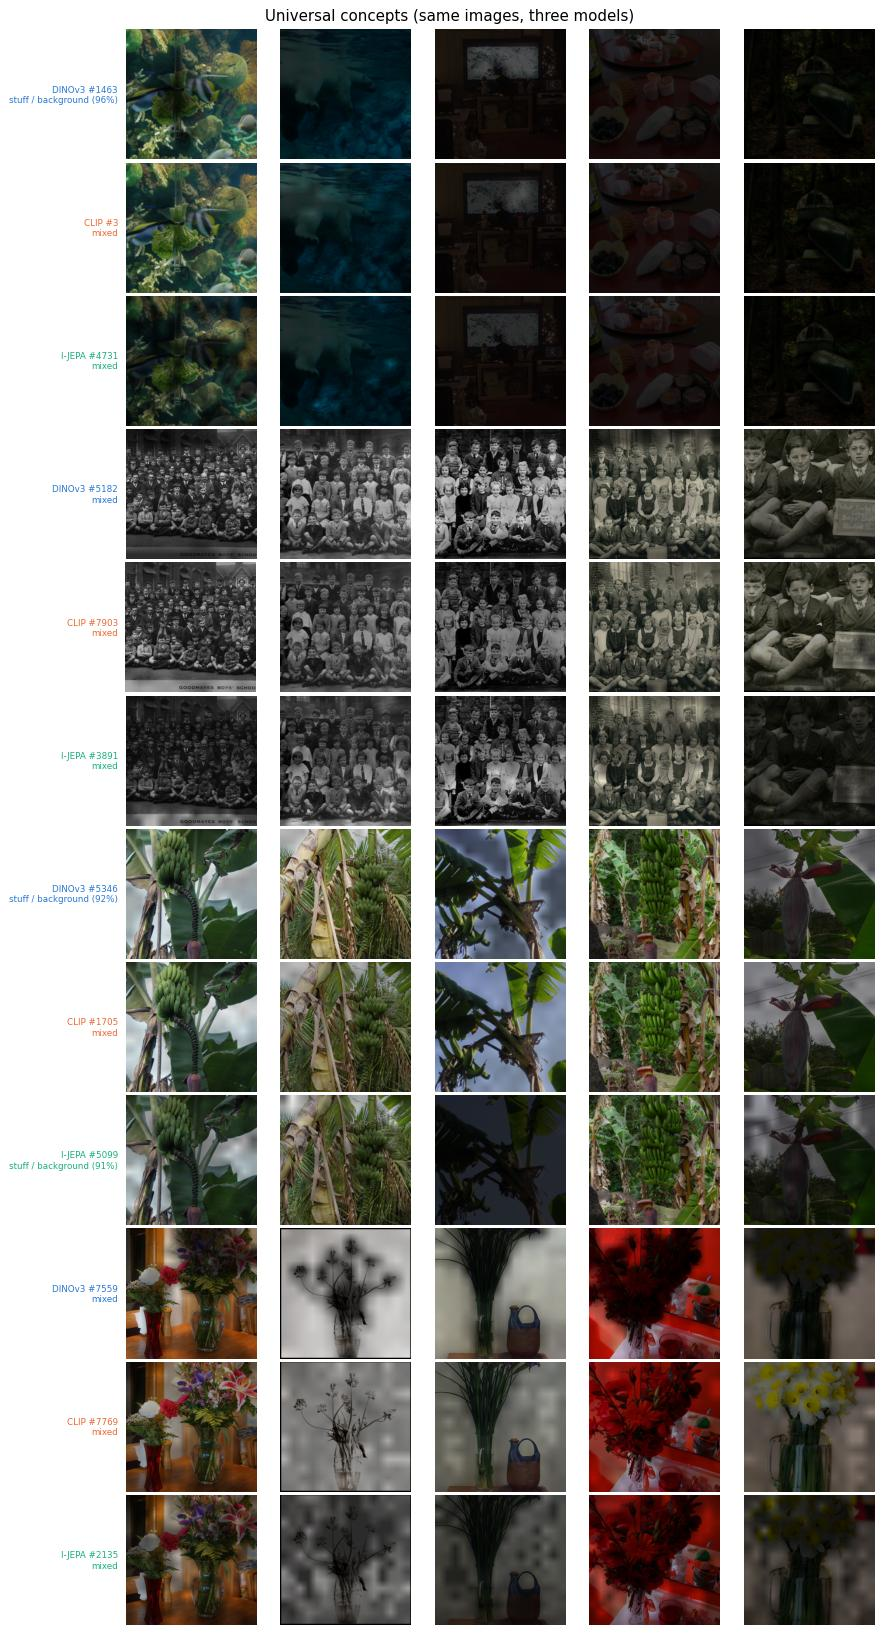

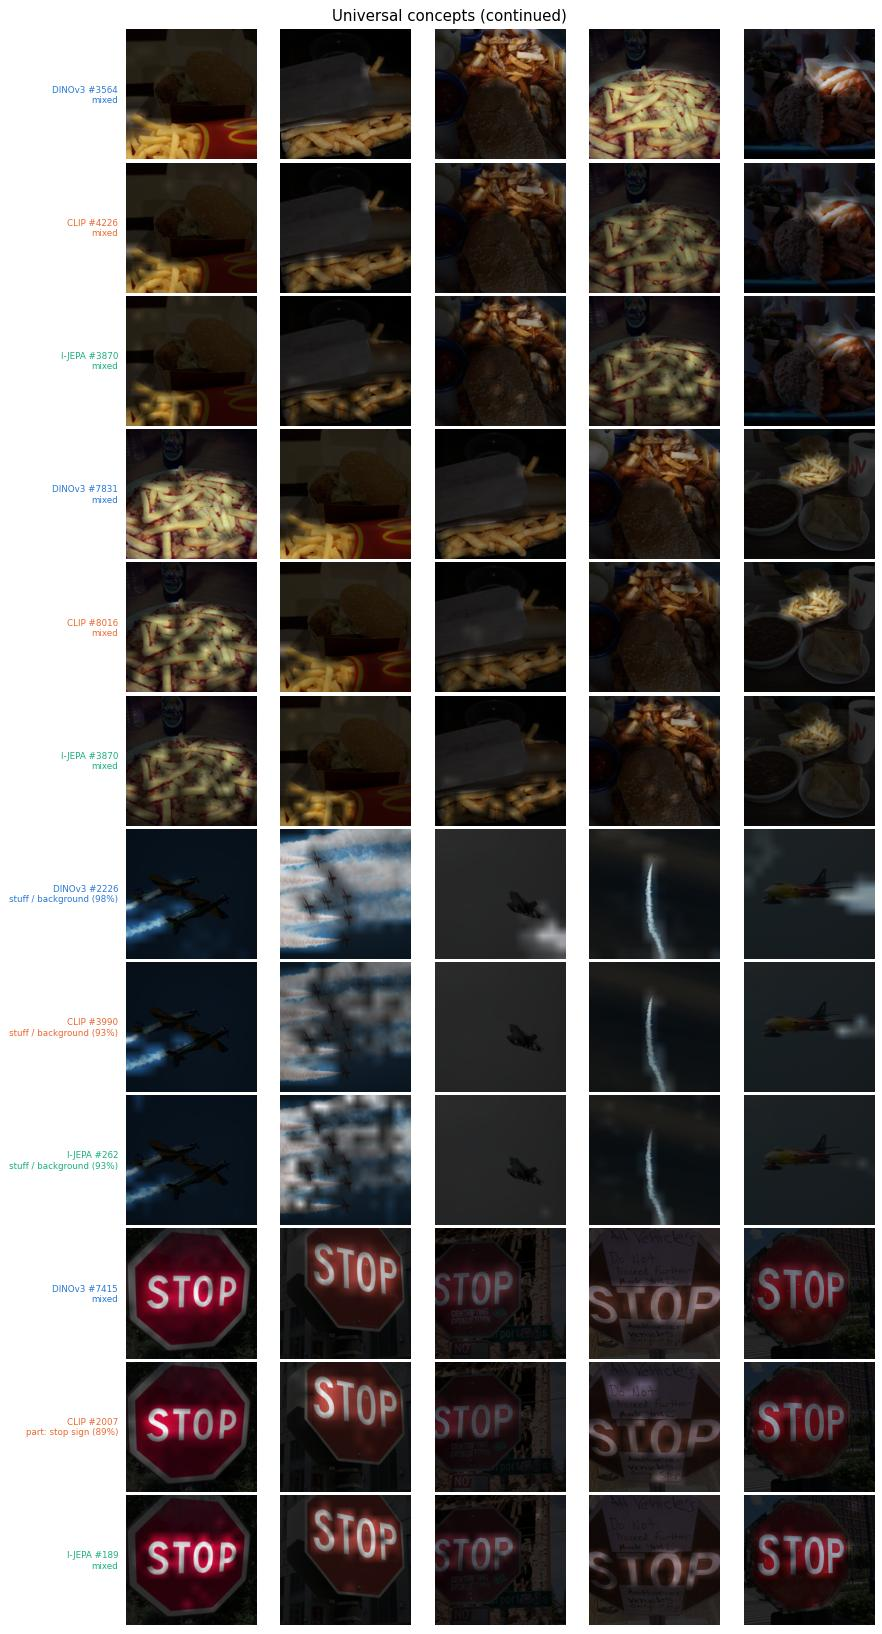

In [22]:
a, b, c = names
jb, jc = MAXC[(a, b)].indices, MAXC[(a, c)].indices
corr_bc = CORR[(b, c)][jb, jc]
score = torch.minimum(torch.minimum(MAXC[(a, b)].values, MAXC[(a, c)].values), corr_bc)
ok = torch.tensor([ST[a]['type'][j] not in ('positional', 'rare', 'dead') for j in range(N_LATENTS)])
score = torch.where(ok, score, -1)
# prefer distinct concepts: skip triplets whose CLIP latent was already used
triplets, used = [], set()
for j in score.argsort(descending=True).tolist():
    if jb[j].item() in used: continue
    triplets.append((j, jb[j].item(), jc[j].item())); used.add(jb[j].item())
    if len(triplets) == 8: break

def triplet_figure(trips, title, fname, n=5):
    if not trips: return
    fig, axes = plt.subplots(3 * len(trips), n, figsize=(1.5 * n + 2.6, 1.5 * 3 * len(trips)), squeeze=False)
    for t_i, trip in enumerate(trips):
        imgs = top_images(a, trip[0], n)
        for m_i, (m, j) in enumerate(zip(names, trip)):
            row = 3 * t_i + m_i
            vmax = max(act_map(m, j, i).max().item() for i in imgs) or 1
            for col, i in enumerate(imgs):
                spotlight(axes[row, col], i, act_map(m, j, i), vmax)
            axes[row, 0].set_ylabel(f'{m} #{j}\n{auto_label(m, j)}', rotation=0, ha='right', va='center',
                                    fontsize=7, labelpad=6, color=COLORS[m])
    fig.suptitle(title, y=1.0)
    plt.tight_layout(pad=0.25)
    savefig(fname)

print('top triplets (DINOv3, CLIP, I-JEPA) and min pairwise corr:')
for trip in triplets:
    print(trip, f'{score[trip[0]]:.2f}', '|', ' / '.join(auto_label(m, j) for m, j in zip(names, trip)))
triplet_figure(triplets[:4], 'Universal concepts (same images, three models)', 'universal_triplets_1')
triplet_figure(triplets[4:8], 'Universal concepts (continued)', 'universal_triplets_2')

The most strongly shared triplets are mostly texture / scene-like concepts. Restricting the DINOv3 side to
object-level latents (object, part, super-category) shows which *object* concepts all three models agree on.

top object-level triplets:
(6312, 4383, 7344) 0.61 | object: clock (78%) / object: clock (78%) / object: clock (61%)
(3502, 5013, 1598) 0.61 | super: food (50%) / mixed / object: broccoli (51%)
(4536, 5546, 3495) 0.59 | object: giraffe (68%) / part: giraffe (82%) / part: giraffe (60%)
(6520, 5211, 2710) 0.59 | object: teddy bear (74%) / object: teddy bear (64%) / object: teddy bear (59%)
(5737, 1229, 5754) 0.59 | super: electronic (85%) / part: laptop (58%) / part: laptop (63%)
(613, 2565, 2748) 0.58 | object: tennis racket (61%) / object: tennis racket (52%) / object: tennis racket (55%)


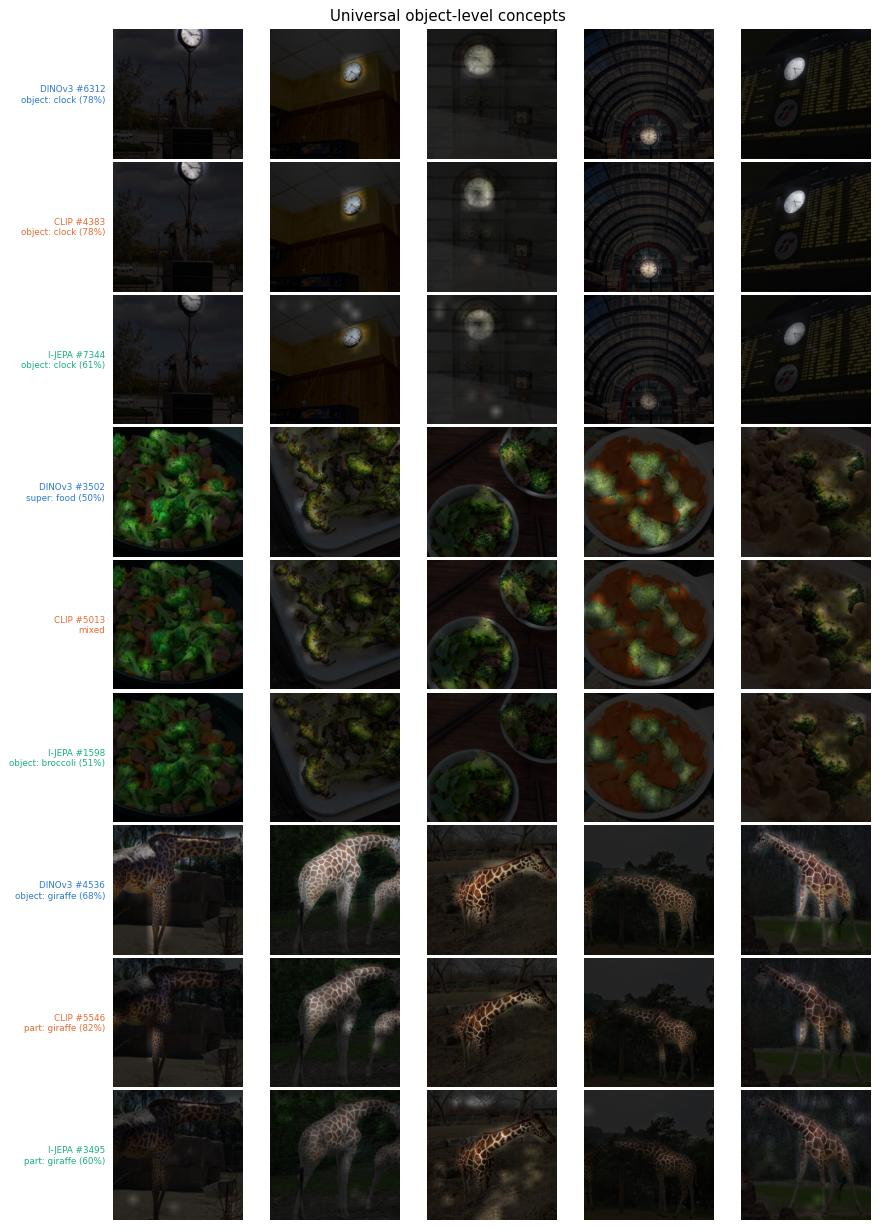

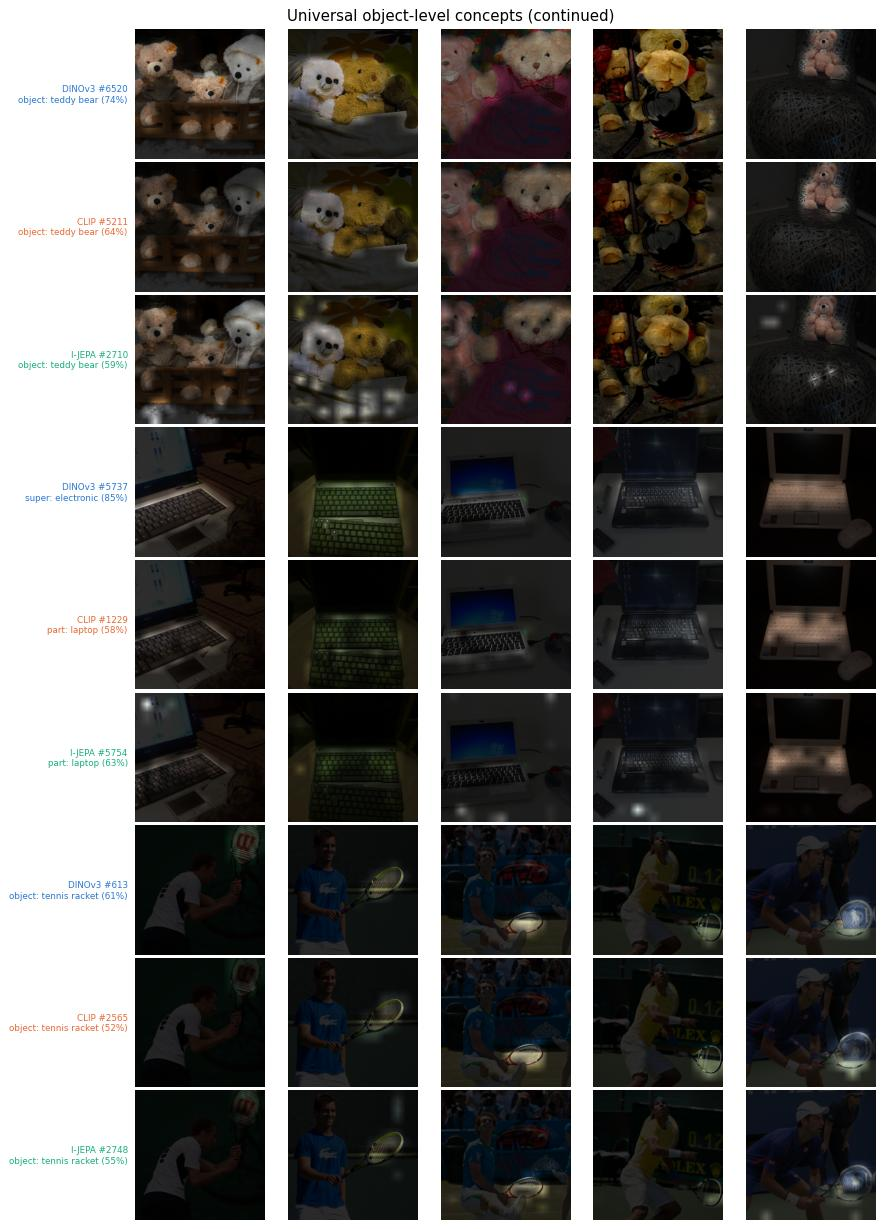

In [23]:
obj_ok = torch.tensor([ST[a]['type'][j] in ('object', 'part', 'super-category') for j in range(N_LATENTS)])
score_obj = torch.where(obj_ok, score, -1)
obj_trips, used = [], set()
for j in score_obj.argsort(descending=True).tolist():
    if score_obj[j] < 0: break
    if jb[j].item() in used: continue
    obj_trips.append((j, jb[j].item(), jc[j].item())); used.add(jb[j].item())
    if len(obj_trips) == 6: break
print('top object-level triplets:')
for trip in obj_trips:
    print(trip, f'{score[trip[0]]:.2f}', '|', ' / '.join(auto_label(m, j) for m, j in zip(names, trip)))
triplet_figure(obj_trips[:3], 'Universal object-level concepts', 'universal_objects_1')
triplet_figure(obj_trips[3:6], 'Universal object-level concepts (continued)', 'universal_objects_2')

### Model-unique concepts
Frequent latents whose best match in *both* other models has correlation < 0.3: concepts only this model's
dictionary carves out.

DINOv3: 4035 unique frequent latents; types: boundary 1, mixed 2270, object 11, part 234, stuff 1372, super-category 147


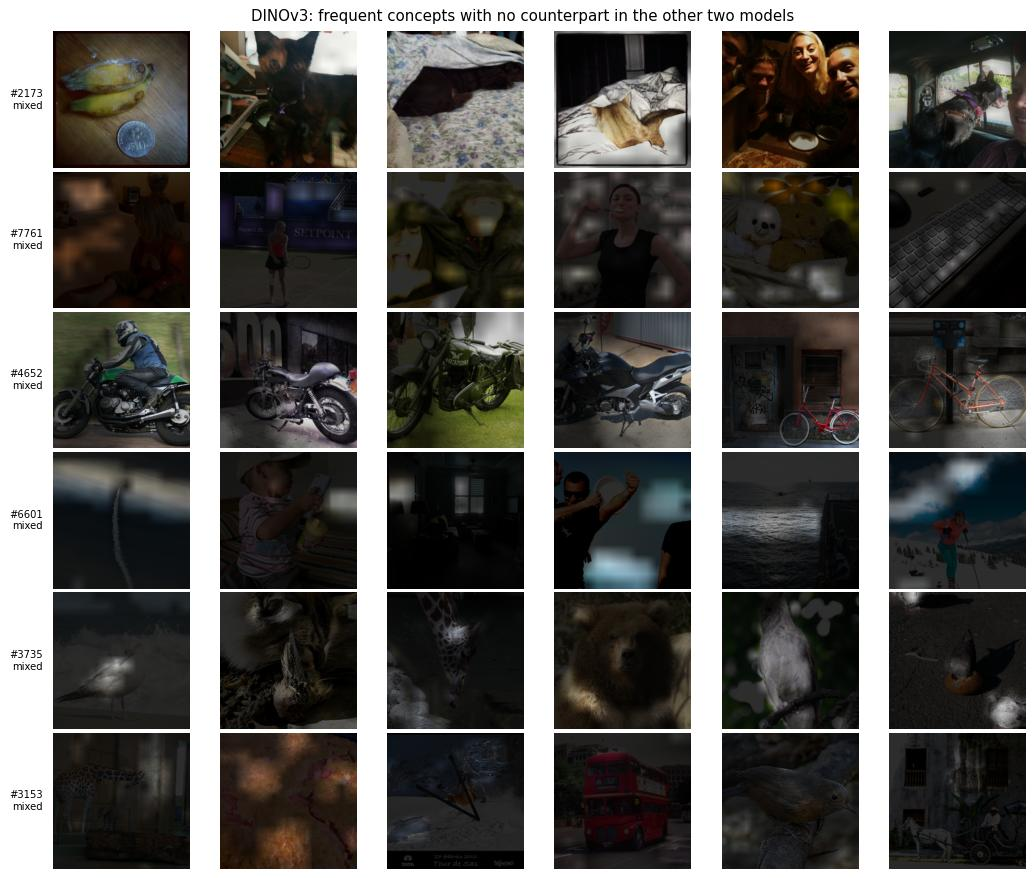

CLIP: 5106 unique frequent latents; types: artifact 33, global 1, mixed 4382, part 130, stuff 535, super-category 25


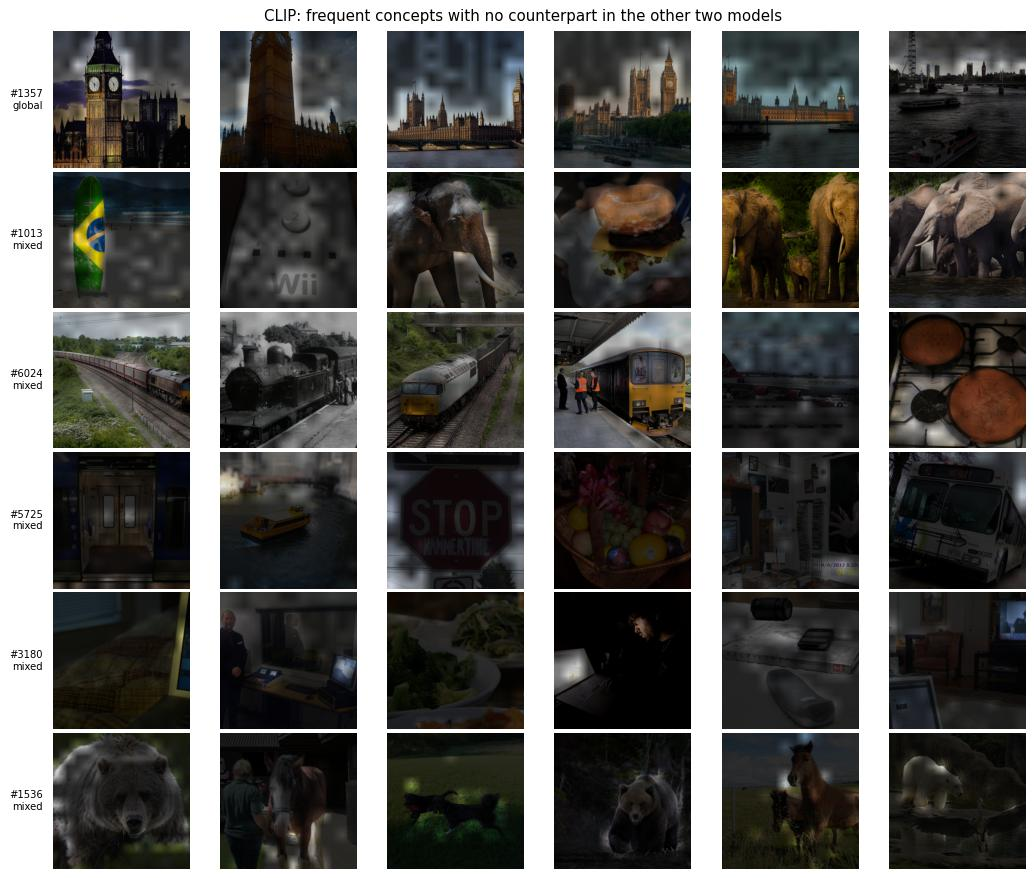

I-JEPA: 5271 unique frequent latents; types: mixed 4215, part 111, positional 3, stuff 927, super-category 15


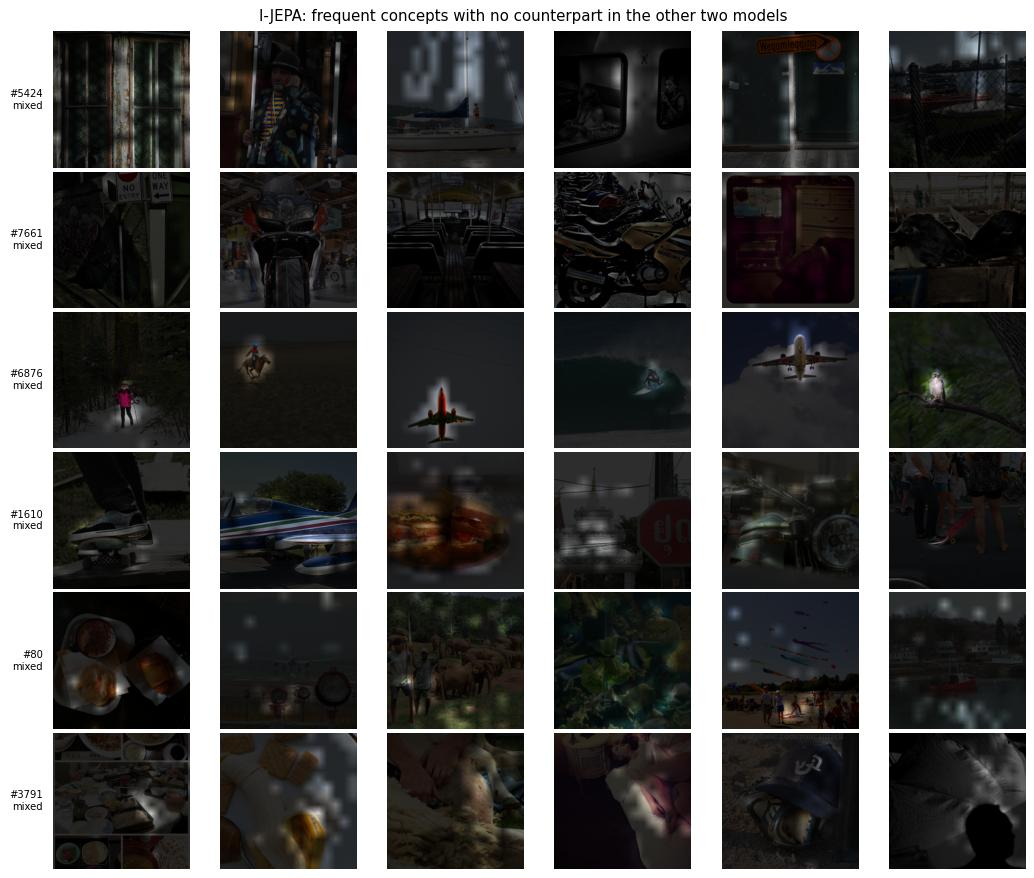

In [24]:
UNIQUE = {}
for m in names:
    o1, o2 = [x for x in names if x != m]
    mc = torch.maximum(MAXC[(m, o1)].values, MAXC[(m, o2)].values)
    cand = np.where((mc < 0.3).numpy() & (ST[m]['count'] >= 4 * MIN_COUNT).numpy()
                    & ~np.isin(ST[m]['type'], ['rare', 'dead']))[0]
    UNIQUE[m] = cand
    u, cnt = np.unique(ST[m]['type'][cand], return_counts=True)
    print(f'{m}: {len(cand)} unique frequent latents; types: ' + ', '.join(f'{k} {v}' for k, v in zip(u, cnt)))
    pick_u = cand[np.argsort(-ST[m]['count'][cand].numpy())[:6]].tolist()
    gallery(m, pick_u, f'{m}: frequent concepts with no counterpart in the other two models', fname=f'unique_{m}')

### "SAE segmentation": one image, three dictionaries
Each patch is coloured by the content latent (object / part / super-category / stuff / boundary / mixed) with the
highest activation. Contiguous colour regions show how each model's dictionary parses the scene.

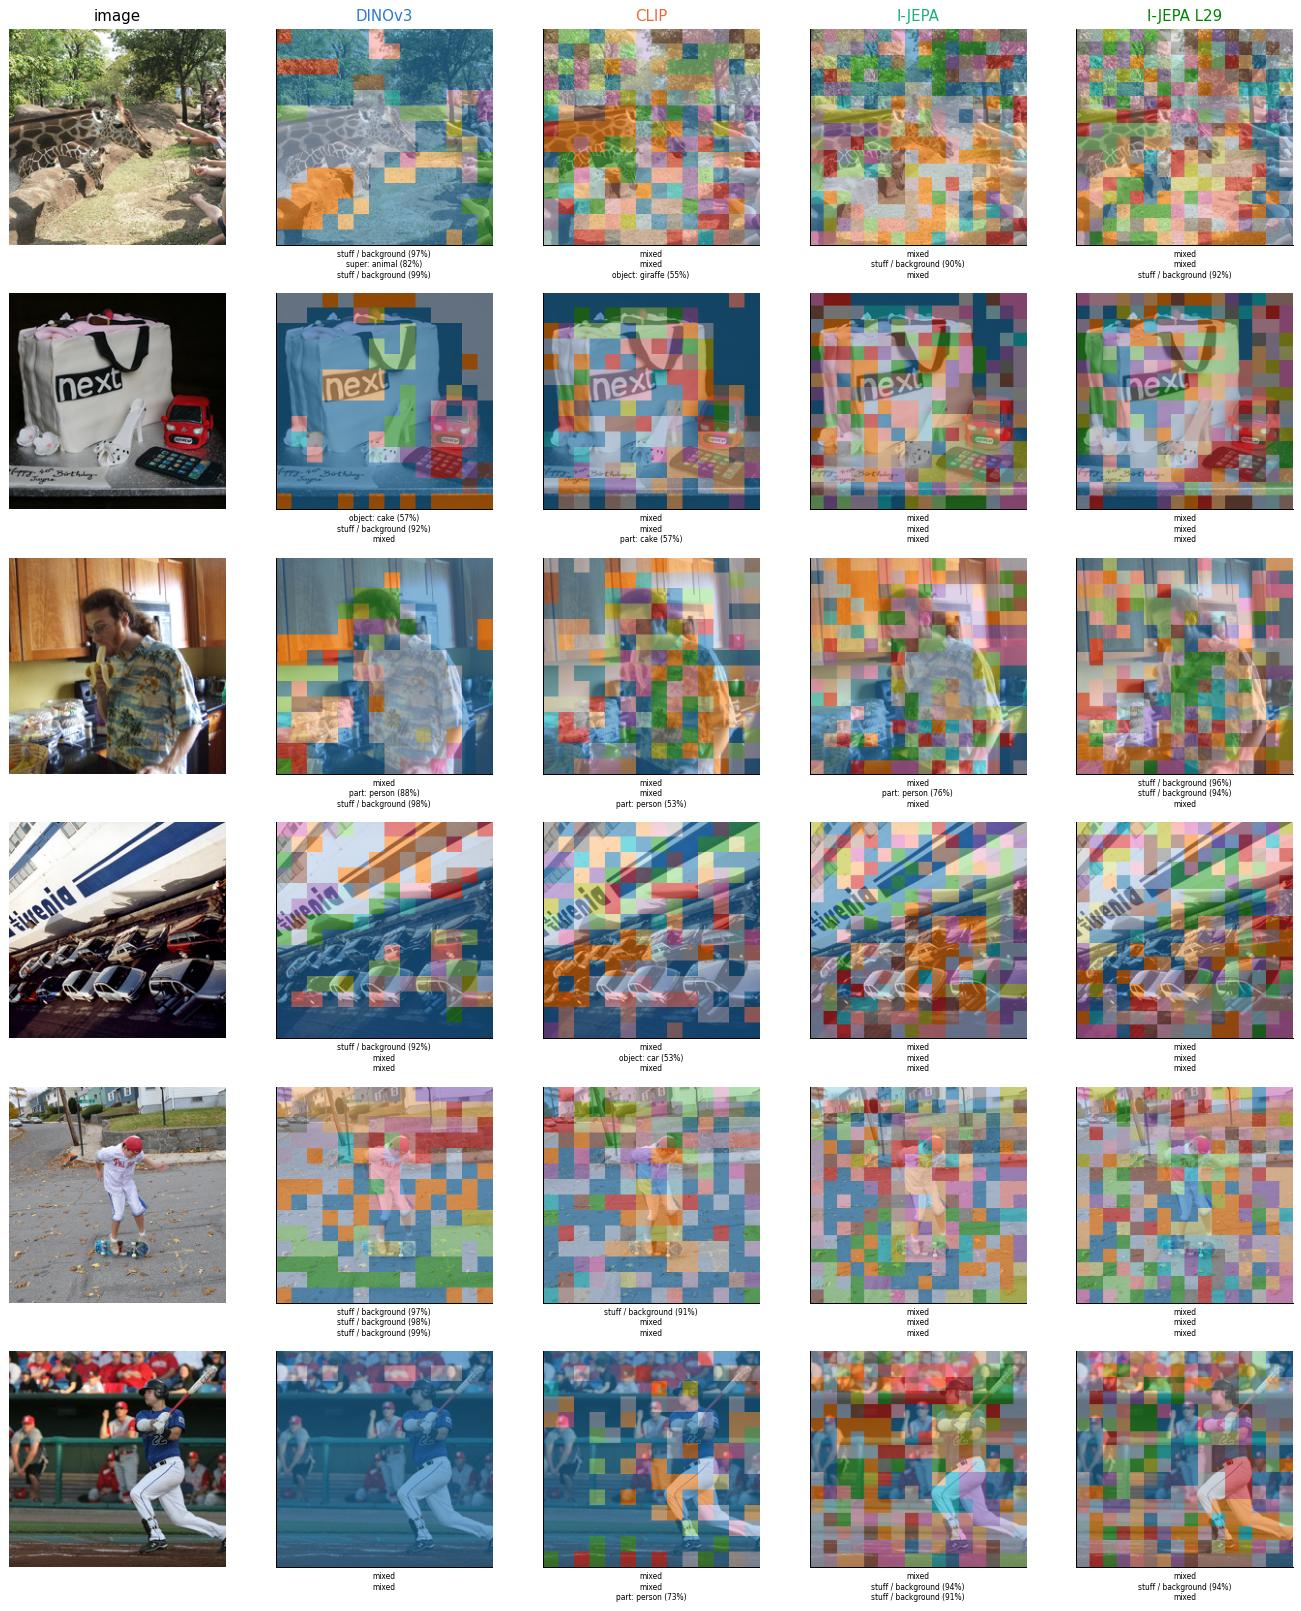

In [25]:
CONTENT = {'object', 'part', 'super-category', 'stuff', 'boundary', 'mixed'}
palette = plt.get_cmap('tab20')(np.arange(20))[:, :3]

def seg_map(name, img):
    c = CODES[name]; g = c['grid']
    i, v = c['idx'][img].long(), c['val'][img].float()
    allowed = torch.tensor([ST[name]['type'][j] in CONTENT for j in range(N_LATENTS)])
    v = torch.where(allowed[i], v, 0)
    top = i.gather(1, v.argmax(1, keepdim=True))[:, 0]
    top = torch.where(v.max(1).values > 0, top, -1).view(g, g)
    uniq = [u for u in top.unique().tolist() if u >= 0]
    counts = {u: int((top == u).sum()) for u in uniq}
    uniq = sorted(uniq, key=lambda u: -counts[u])
    rgb = np.zeros((g, g, 3)); alpha = np.zeros((g, g))
    for k, u in enumerate(uniq):
        rgb[top.numpy() == u] = palette[k % 20]; alpha[top.numpy() == u] = 1
    return rgb, alpha, uniq[:3]

imgs_seg = [i for i in range(N_VAL_IMAGES) if len(set(LABELS[14]['cat'][i].tolist()) - {BG}) >= 2][:6]
fig, axes = plt.subplots(len(imgs_seg), 1 + len(ALL), figsize=(3 * (1 + len(ALL)), 3 * len(imgs_seg)))
for row, img in enumerate(imgs_seg):
    spotlight(axes[row, 0], img)
    axes[0, 0].set_title('image')
    for col, n in enumerate(ALL, 1):
        rgb, alpha, top3 = seg_map(n, img)
        g = CODES[n]['grid']
        big = F.interpolate(torch.tensor(rgb).permute(2, 0, 1)[None].float(), size=(IMG, IMG), mode='nearest')[0].permute(1, 2, 0)
        mix = 0.45 * VAL_IMGS[img].float() / 255 + 0.55 * big
        axes[row, col].imshow(mix.numpy()); axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        axes[row, col].set_xlabel('\n'.join(auto_label(n, j)[:34] for j in top3), fontsize=6)
        if row == 0: axes[0, col].set_title(n, color=COLORS[n])
plt.tight_layout(); savefig('sae_segmentation')

## 8. Context: are the raw representations similar?
Linear CKA between raw patch features (1000 val images, common 14x14 grid), next to the probe results.

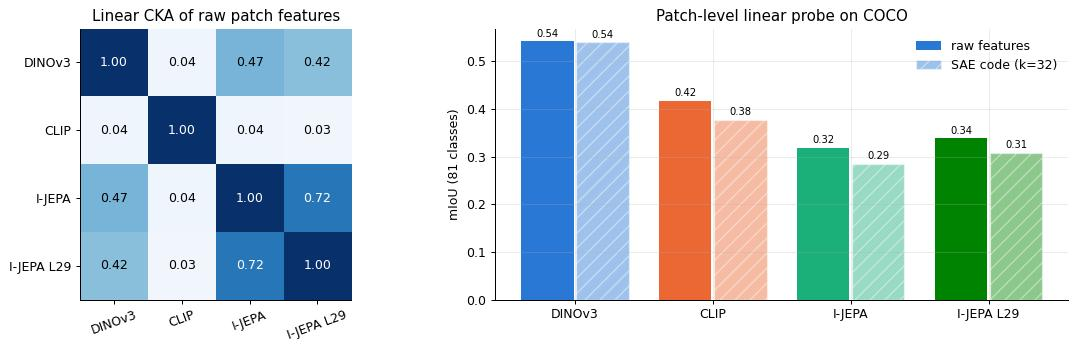

In [26]:
@torch.no_grad()
def linear_cka(X, Y):
    X = X.to(DEV).float(); Y = Y.to(DEV).float()
    X = X - X.mean(0); Y = Y - Y.mean(0)
    return ((X.T @ Y).norm() ** 2 / ((X.T @ X).norm() * (Y.T @ Y).norm())).item()

cka = np.eye(len(ALL))
for i_, a_ in enumerate(ALL):
    for j_, b_ in enumerate(ALL):
        if i_ < j_:
            cka[i_, j_] = cka[j_, i_] = linear_cka(R[a_]['cka_x'], R[b_]['cka_x'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(cka, cmap='Blues', vmin=0, vmax=1)
for i_ in range(len(ALL)):
    for j_ in range(len(ALL)):
        axes[0].text(j_, i_, f'{cka[i_, j_]:.2f}', ha='center', va='center', color='white' if cka[i_, j_] > 0.6 else 'black')
axes[0].set_xticks(range(len(ALL)), ALL, rotation=20); axes[0].set_yticks(range(len(ALL)), ALL); axes[0].grid(False)
axes[0].set_title('Linear CKA of raw patch features')
x = np.arange(len(ALL))
axes[1].bar(x - 0.2, [R[n]['probe_raw']['miou'] for n in ALL], 0.38, color=[COLORS[n] for n in ALL], label='raw features')
axes[1].bar(x + 0.2, [R[n]['probe_sae']['miou'] for n in ALL], 0.38, color=[COLORS[n] for n in ALL], alpha=0.45,
            hatch='//', edgecolor='white', label='SAE code (k=32)')
for k, n in enumerate(ALL):
    axes[1].text(k - 0.2, R[n]['probe_raw']['miou'] + 0.01, f"{R[n]['probe_raw']['miou']:.2f}", ha='center', fontsize=8)
    axes[1].text(k + 0.2, R[n]['probe_sae']['miou'] + 0.01, f"{R[n]['probe_sae']['miou']:.2f}", ha='center', fontsize=8)
axes[1].set_xticks(x, ALL); axes[1].set(ylabel='mIoU (81 classes)', title='Patch-level linear probe on COCO')
axes[1].legend(frameon=False)
plt.tight_layout(); savefig('cka_probe')

## 9. Summary table

In [27]:
summary = {}
for n in ALL:
    live = ST[n]['count'] >= MIN_COUNT
    ty = ST[n]['type']
    summary[n] = {
        'val FVU': R[n]['fvu'],
        'dead / rare latents': np.mean(np.isin(ty, ['dead', 'rare'])),
        'object (whole)': np.mean(ty == 'object'),
        'object part': np.mean(ty == 'part'),
        'object-level total (object+part+super)': np.mean(np.isin(ty, ['object', 'part', 'super-category'])),
        'stuff / background': np.mean(ty == 'stuff'),
        'positional': np.mean(ty == 'positional'),
        'global': np.mean(ty == 'global'),
        'artifact': np.mean(ty == 'artifact'),
        'median purity (live)': ST[n]['purity'][live].median().item(),
        'median coverage (live)': np.nanmedian(ST[n]['coverage'][live].numpy()),
        'categories with F1>=0.5 latent': sum(BEST_F1[n].values[c] >= 0.5 for c in present).item(),
        'mean best-latent F1': np.mean([BEST_F1[n].values[c].item() for c in present]),
        'shared by all three': np.mean(SHARE[n][live.numpy()] == 'all three') if n in SHARE else np.nan,
        'unique': np.mean(SHARE[n][live.numpy()] == 'unique') if n in SHARE else np.nan,
        'probe mIoU raw': R[n]['probe_raw']['miou'],
        'probe mIoU SAE': R[n]['probe_sae']['miou'],
    }
print(f"{'':42s}" + ''.join(f'{n:>11s}' for n in ALL))
for k in summary[ALL[0]]:
    vals = [summary[n][k] for n in ALL]
    fmt = (lambda v: f'{v:11d}') if isinstance(vals[0], (int, np.integer)) else (
        (lambda v: f'{v:11.3f}') if 'FVU' in k or 'F1' in k or 'median' in k or 'mIoU' in k else (lambda v: f'{v:11.1%}'))
    print(f'{k:42s}' + ''.join(fmt(v) for v in vals))
json.dump({n: {k: float(v) for k, v in s.items()} for n, s in summary.items()}, open(f'{OUT}/summary.json', 'w'), indent=1)
print(f'\ntotal runtime: {(time.time() - T0) / 60:.1f} min')

                                               DINOv3       CLIP     I-JEPA I-JEPA L29
val FVU                                         0.221      0.110      0.193      0.233
dead / rare latents                              0.0%       0.3%       0.0%       1.0%
object (whole)                                   3.8%       0.9%       0.2%       0.4%
object part                                     11.5%       7.7%       6.4%      11.2%
object-level total (object+part+super)          20.7%      10.4%       7.6%      15.8%
stuff / background                              33.6%      18.7%      19.1%      20.4%
positional                                       0.1%       0.0%       0.1%       0.2%
global                                           0.0%       0.0%       0.0%       0.0%
artifact                                         0.0%       0.5%       0.0%       0.2%
median purity (live)                            0.096      0.089      0.091      0.114
median coverage (live)                     

## 10. Conclusions

**1. DINOv3 has by far the most object-level dictionary.** 20.7% of its latents are object-level (whole object,
object part or super-category), against 10.4% for CLIP and 7.6% for I-JEPA. It has 313 whole-object latents
(CLIP 71, I-JEPA 13), a dedicated latent with F1 >= 0.5 for 38 of the 80 COCO categories (CLIP 23, I-JEPA 2), and the
highest object coverage (median 0.20, against 0.06 and 0.09). The second DINOv3 SAE (different seed) gives an almost
identical taxonomy, so these gaps are not SAE noise.

**2. Does JEPA learn more object-level concepts than CLIP? At the final layer, no. At its best layer, it learns more
object parts but fewer whole categories.** Final-layer I-JEPA has the least object-level dictionary of the three.
Its "category" latents behave like part and texture detectors: its best giraffe latent fires on the coat pattern,
not on the silhouette. The depth sweep shows that I-JEPA's patch features are most linearly decodable at block 29/32
and get worse at the output. An SAE on block 29 roughly doubles the object-level share (7.6% -> 15.8%, now *above*
CLIP's 10.4%, mostly part latents: 917 vs CLIP's 628) and gives 4x more dedicated categories (2 -> 8). That is still
far fewer clean category detectors than CLIP (23). So I-JEPA's concepts are object-*part*-level, CLIP's are more
*category*-level (captions name whole objects), and DINOv3 has both. Caveat: I-JEPA is a ViT-H trained only on
ImageNet-1k, while the other two saw far more (and more diverse) data.

**3. Shared concepts are the exception, and DINOv3 is the hub.** Even two SAEs trained on the *same* DINOv3 features
agree (best-match correlation >= 0.5) on only 54% of latents, a practical upper bound. Across models it is 14%
(DINOv3 -> CLIP), 6% (DINOv3 -> I-JEPA) and 2% (CLIP -> I-JEPA). Only 2-4% of latents are shared by all three
models. CLIP and I-JEPA each share much more with DINOv3 than with each other. I-JEPA's block 29 shares twice as
much with DINOv3 as its final layer (12% vs 6%).

**4. What is shared is objects and textures.** Whole-object latents are by far the most universal type: 23-25% of
DINOv3's and CLIP's object latents, and 8 of I-JEPA's 13, are shared by all three models, against < 6% for every
other type. The objects agreed on are visually distinctive categories (clocks, teddy bears and tennis rackets are whole-object latents in all three models; for giraffes and laptops, CLIP and I-JEPA match with a part-level latent; broccoli is object-level in I-JEPA but super-category / mixed in DINOv3 / CLIP). The single strongest triplets are texture/scene concepts (underwater scenes, crowds of
faces in old photos, banana foliage, flower bouquets).

**5. CLIP's final-layer patch tokens are peculiar.** Its SAE has the lowest FVU (0.11 vs 0.19-0.22). 3.6% of its
patch tokens form a high-norm mode (3-6x the median norm), and 39 of its latents specialise on these register-like
tokens. Its probe accuracy plateaus from block 10 onwards, while DINOv3 keeps improving to the last block. Its
linear CKA to the other models is ~0.04, even though 14% of DINOv3's latents have a clear CLIP counterpart. A few
dominant high-norm directions most likely drive both the low FVU and the near-zero CKA, which is a reminder that
global similarity indices and concept-level comparisons can disagree. (Note that DINOv3's and I-JEPA's final outputs
pass through a final LayerNorm, which evens out token norms. I-JEPA's block 29, taken before that norm, does show a
small high-norm mode of 0.26%.)

**6. The SAEs keep the semantics.** A linear probe on the 32-sparse SAE code recovers about 90-100% of the raw-feature probe mIoU (DINOv3 0.540 vs 0.542, CLIP 0.378 vs 0.418, I-JEPA 0.286 vs 0.318), so the conclusions above are about
the models, not about information the SAEs threw away.